# Gráficos gerados a partir da aula prática de Reologia
---

Aluno: Abner Vieira Pereira

In [1048]:
import numpy as np
import pandas as pd
from IPython.display import Image, display, Math, Markdown
import matplotlib.pyplot as plt
import scienceplots
from scipy.optimize import curve_fit

A principal vantagem da geometria cone-placa é que tanto a tensão de cisalhamento ($\tau$) quanto a taxa de cisalhamento ($\dot{\gamma}$) são independentes da posição e podem ser facilmente calculados através das seguintes equações:

\begin{equation}
    \tau = \frac{3\,M}{2\,\pi\,R^3}
\end{equation}

onde:

- M = torque em N.m;
- R = raio do cone em m.



\begin{equation}
    \dot{\gamma} = \frac{\Omega}{\beta}
\end{equation}

onde:

- $\Omega$ = velocidade angular em rad/s;
- $\beta$ = ângulo do cone em rad;


### Geometria do Reômetro do tipo cone-placa

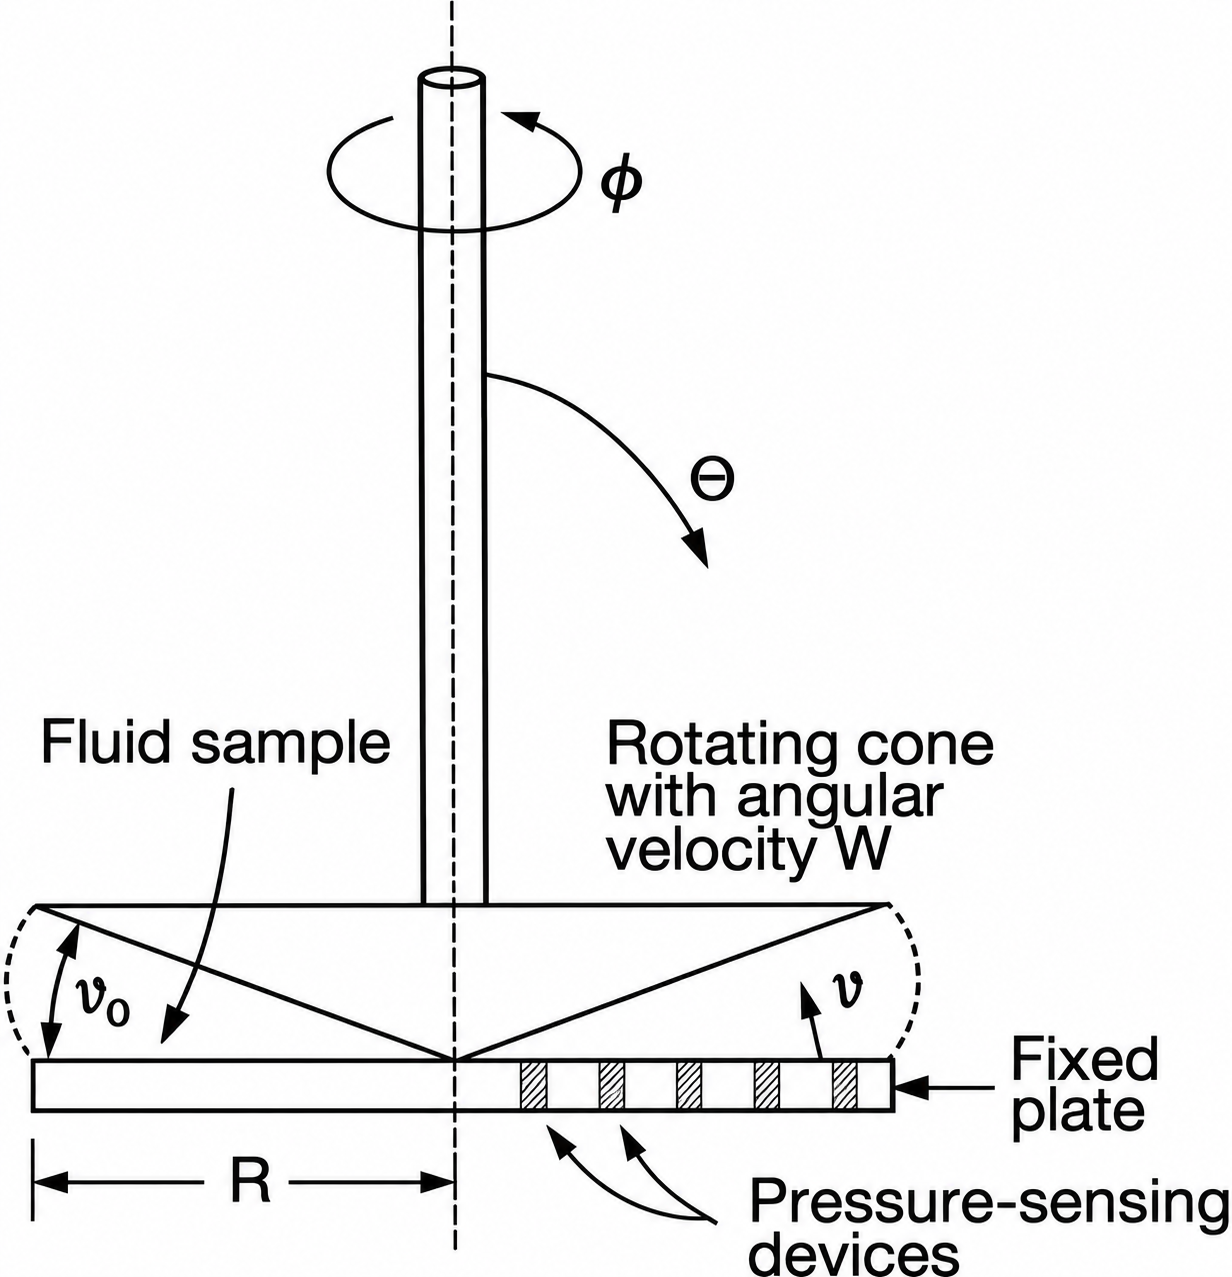

In [1049]:
Image("reômetro cone-placa.png", width=500)

In [1050]:
# Dicionário contendo os parâmetros geométricos do cone

dic = {
    'R':(35/1000) / 2,         # O diâmetro do cone utilizado possuía 35mm
    'beta':(np.pi * 2) / 180   # O ângulo era 2º
}

## 1.0 Goma Guar

Nesse primeiro ensaio, a taxa de cisalhamento ($\dot{\gamma}$) foi controlada. A Goma guar apresentava uma concentração de 0,55% m.m. E a temperatura do ensaio foi de 25°C.

In [1051]:
# Exportando a planilha de dados obtidos do reômetro

data = "Flow curves 10 20.xlsx"

In [1052]:
guar = pd.read_excel(data, sheet_name=0)
guar.head()

,SegIndex,t in s,t_seg in s,M in µN·m,Ω in rad/s
0,1|1,121.525612,1.002022,0.257978,0.000334
1,1|2,122.525650,2.002060,0.373993,0.000347
2,1|3,123.525673,3.002083,0.405884,0.000347
3,1|4,124.525726,4.002136,0.435687,0.000348
4,1|5,125.525742,5.002151,0.443012,0.000349


In [1053]:
# Criando fileiras com conversões

guar["M in N.m"] = guar["M in µN·m"] * 10**-6
guar.head()

,SegIndex,t in s,t_seg in s,M in µN·m,Ω in rad/s,M in N.m
0,1|1,121.525612,1.002022,0.257978,0.000334,2.579781e-07
1,1|2,122.525650,2.002060,0.373993,0.000347,3.739926e-07
2,1|3,123.525673,3.002083,0.405884,0.000347,4.058837e-07
3,1|4,124.525726,4.002136,0.435687,0.000348,4.356872e-07
4,1|5,125.525742,5.002151,0.443012,0.000349,4.430117e-07


In [1054]:
guar["τ in Pa"] = (3 * guar["M in N.m"]) / (2 * np.pi * (dic["R"]**3))
guar.head()

,SegIndex,t in s,t_seg in s,M in µN·m,Ω in rad/s,M in N.m,τ in Pa
0,1|1,121.525612,1.002022,0.257978,0.000334,2.579781e-07,0.022983
1,1|2,122.525650,2.002060,0.373993,0.000347,3.739926e-07,0.033319
2,1|3,123.525673,3.002083,0.405884,0.000347,4.058837e-07,0.036160
3,1|4,124.525726,4.002136,0.435687,0.000348,4.356872e-07,0.038815
4,1|5,125.525742,5.002151,0.443012,0.000349,4.430117e-07,0.039468


In [1055]:
guar["γ̇ in 1/s"] = (guar["Ω in rad/s"] / dic["beta"]).round(3)
guar.head()

,SegIndex,t in s,t_seg in s,M in µN·m,Ω in rad/s,M in N.m,τ in Pa,γ̇ in 1/s
0,1|1,121.525612,1.002022,0.257978,0.000334,2.579781e-07,0.022983,0.01
1,1|2,122.525650,2.002060,0.373993,0.000347,3.739926e-07,0.033319,0.01
2,1|3,123.525673,3.002083,0.405884,0.000347,4.058837e-07,0.036160,0.01
3,1|4,124.525726,4.002136,0.435687,0.000348,4.356872e-07,0.038815,0.01
4,1|5,125.525742,5.002151,0.443012,0.000349,4.430117e-07,0.039468,0.01


In [1056]:
guar["γ"] = guar["γ̇ in 1/s"] * guar["t_seg in s"]
guar.head()

,SegIndex,t in s,t_seg in s,M in µN·m,Ω in rad/s,M in N.m,τ in Pa,γ̇ in 1/s,γ
0,1|1,121.525612,1.002022,0.257978,0.000334,2.579781e-07,0.022983,0.01,0.010020
1,1|2,122.525650,2.002060,0.373993,0.000347,3.739926e-07,0.033319,0.01,0.020021
2,1|3,123.525673,3.002083,0.405884,0.000347,4.058837e-07,0.036160,0.01,0.030021
3,1|4,124.525726,4.002136,0.435687,0.000348,4.356872e-07,0.038815,0.01,0.040021
4,1|5,125.525742,5.002151,0.443012,0.000349,4.430117e-07,0.039468,0.01,0.050022


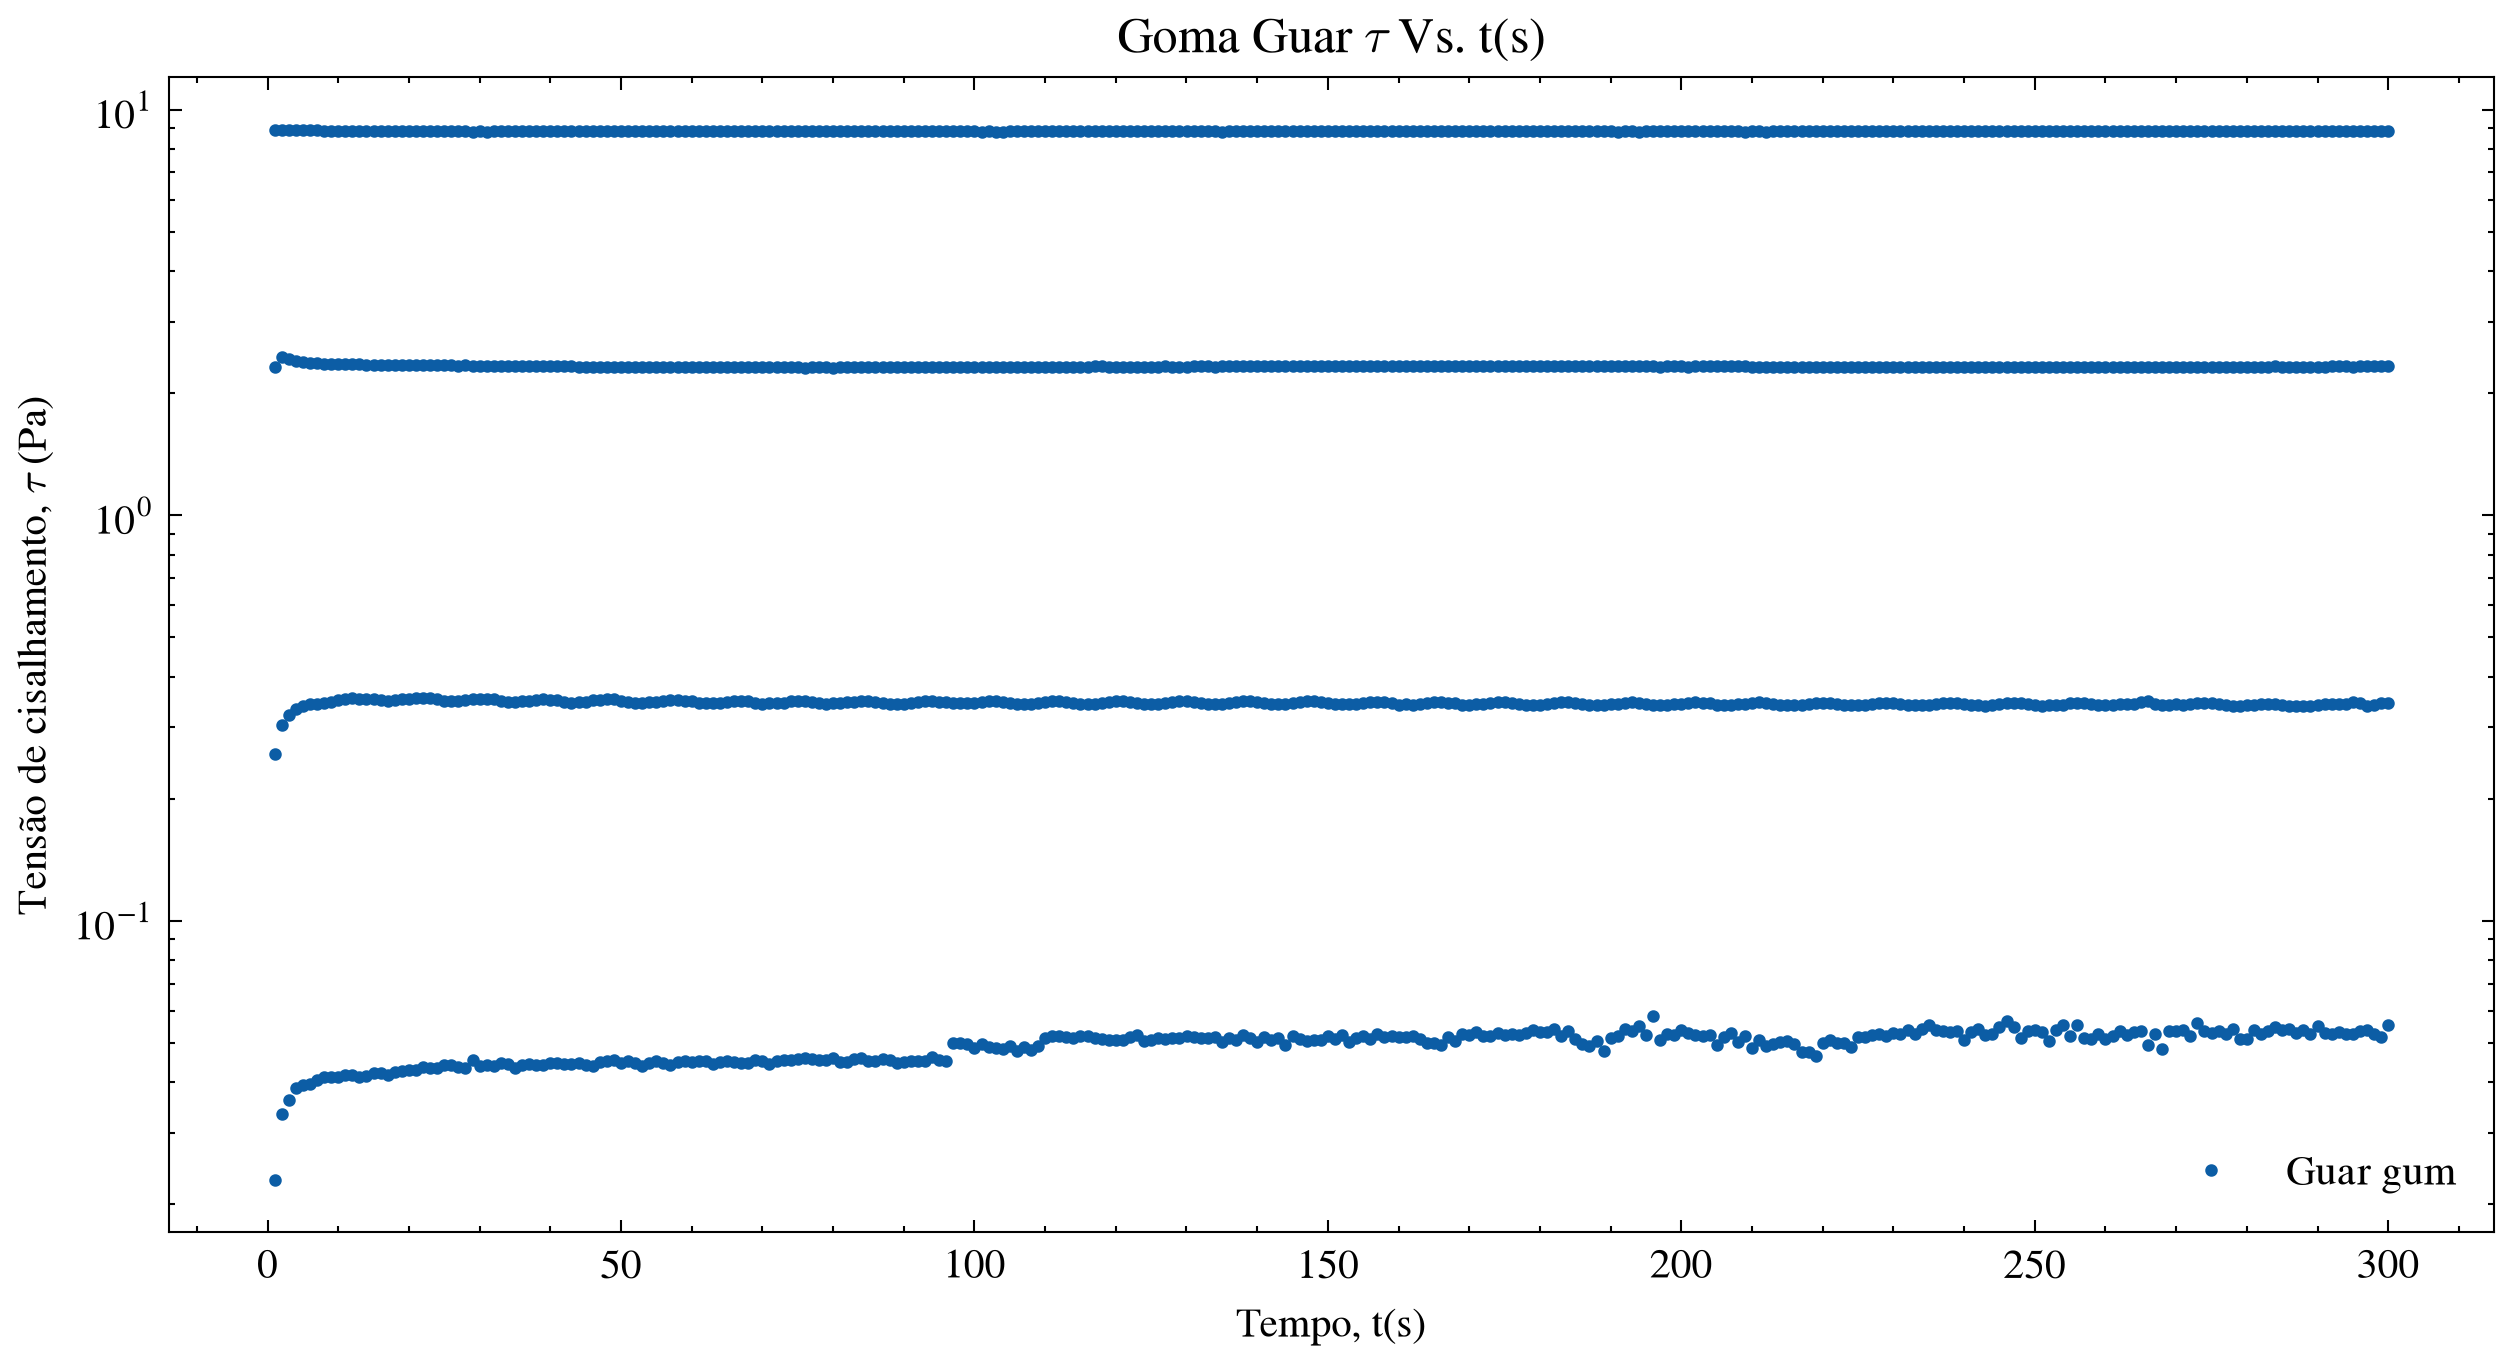

In [1057]:
# Plotagem

plt.style.use(["science", "no-latex"])

plt.figure(figsize=(10,5), dpi=300)
plt.semilogy(guar["t_seg in s"], guar["τ in Pa"], "o", markersize=2, label="Guar gum")
plt.xlabel(r"Tempo, t(s)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.title(r"Goma Guar $\tau$ Vs. t(s)")
plt.legend()
plt.show()

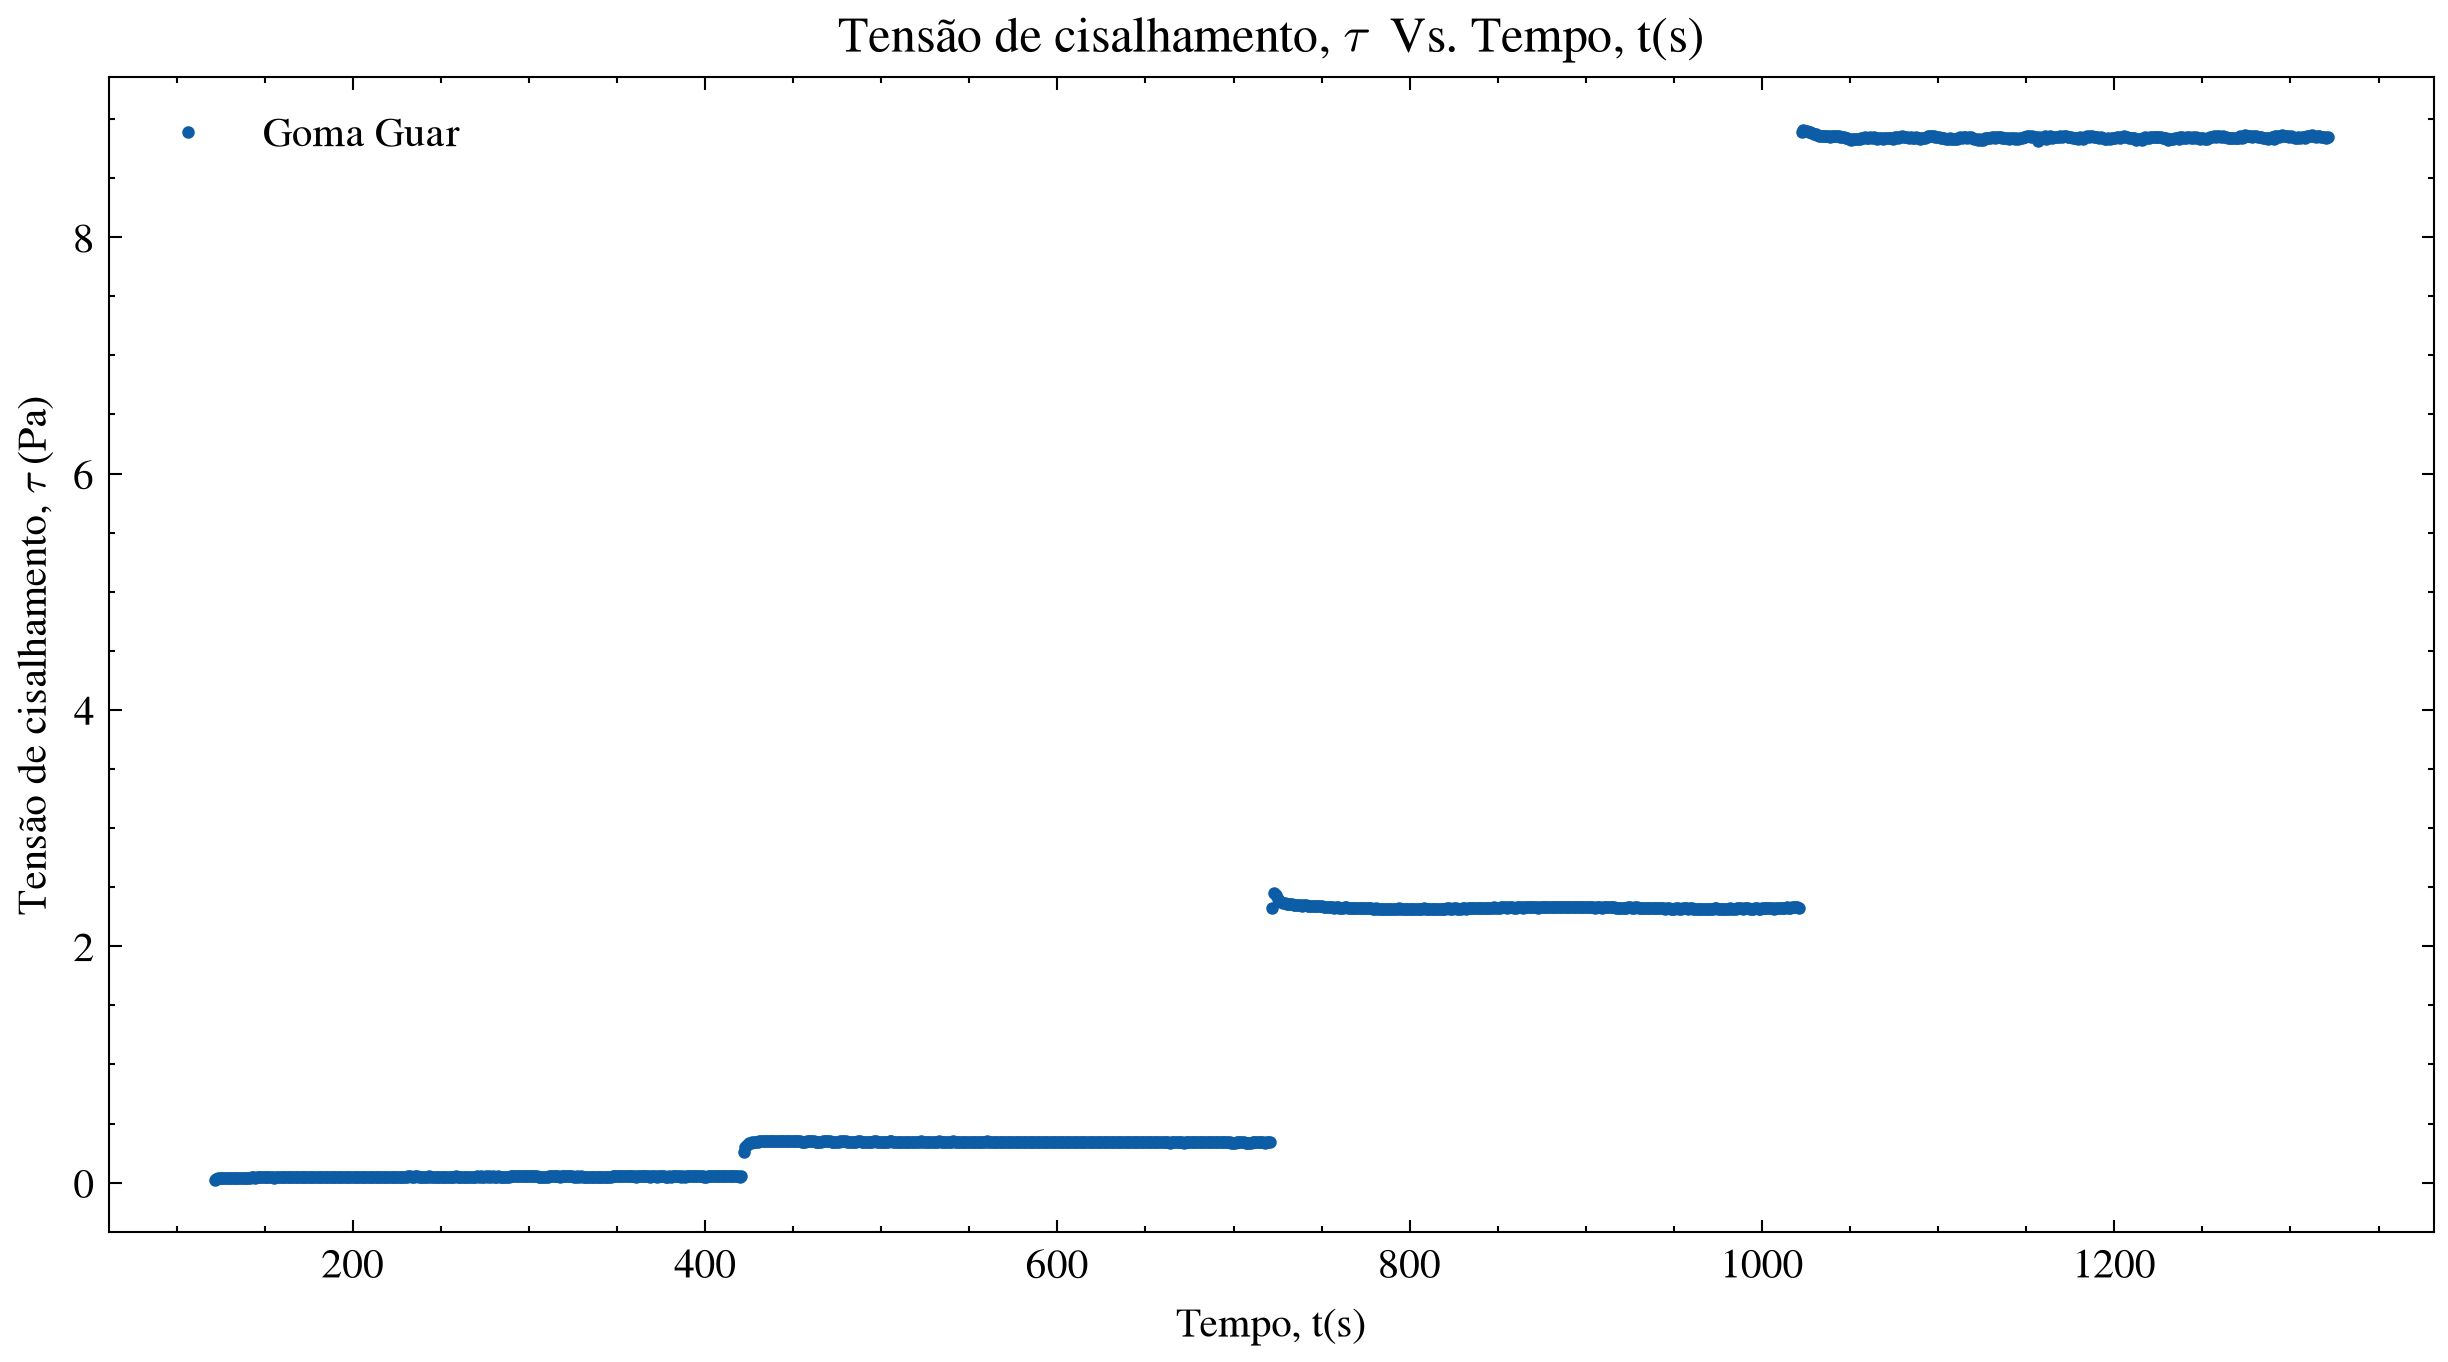

In [1058]:
plt.style.use(["science", "no-latex"])

plt.figure(figsize=(10,5), dpi=300)
plt.plot(guar["t in s"], guar["τ in Pa"], "o", markersize=2, label="Goma Guar")
plt.xlabel(r"Tempo, t(s)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.title(r"Tensão de cisalhamento, $\tau$  Vs. Tempo, t(s)")
plt.legend()
plt.show()

In [1059]:
# Separando as planilhas por shear rate

guar["seg"] = guar["SegIndex"].str.split("|").str[0].astype(int)

for s, g in guar.groupby("seg"):
    g.to_excel(f"guar_seg_{s}.xlsx", index=False)

In [1060]:
data_guar_1 = pd.read_excel("guar_seg_1.xlsx")
data_guar_1.tail()

,SegIndex,t in s,t_seg in s,M in µN·m,Ω in rad/s,M in N.m,τ in Pa,γ̇ in 1/s,γ,seg
295,1|296,416.525848,296.002258,0.599786,0.000350,5.997863e-07,0.053435,0.01,2.960023,1
296,1|297,417.525879,297.002289,0.604636,0.000350,6.046362e-07,0.053867,0.01,2.970023,1
297,1|298,418.525909,298.002319,0.590449,0.000348,5.904489e-07,0.052603,0.01,2.980023,1
298,1|299,419.525940,299.002350,0.581420,0.000350,5.814205e-07,0.051799,0.01,2.990023,1
299,1|300,420.525970,300.000427,0.621159,0.000349,6.211588e-07,0.055339,0.01,3.000004,1


C:\Users\abner.pereira\AppData\Local\Temp\ipykernel_20688\1569525556.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


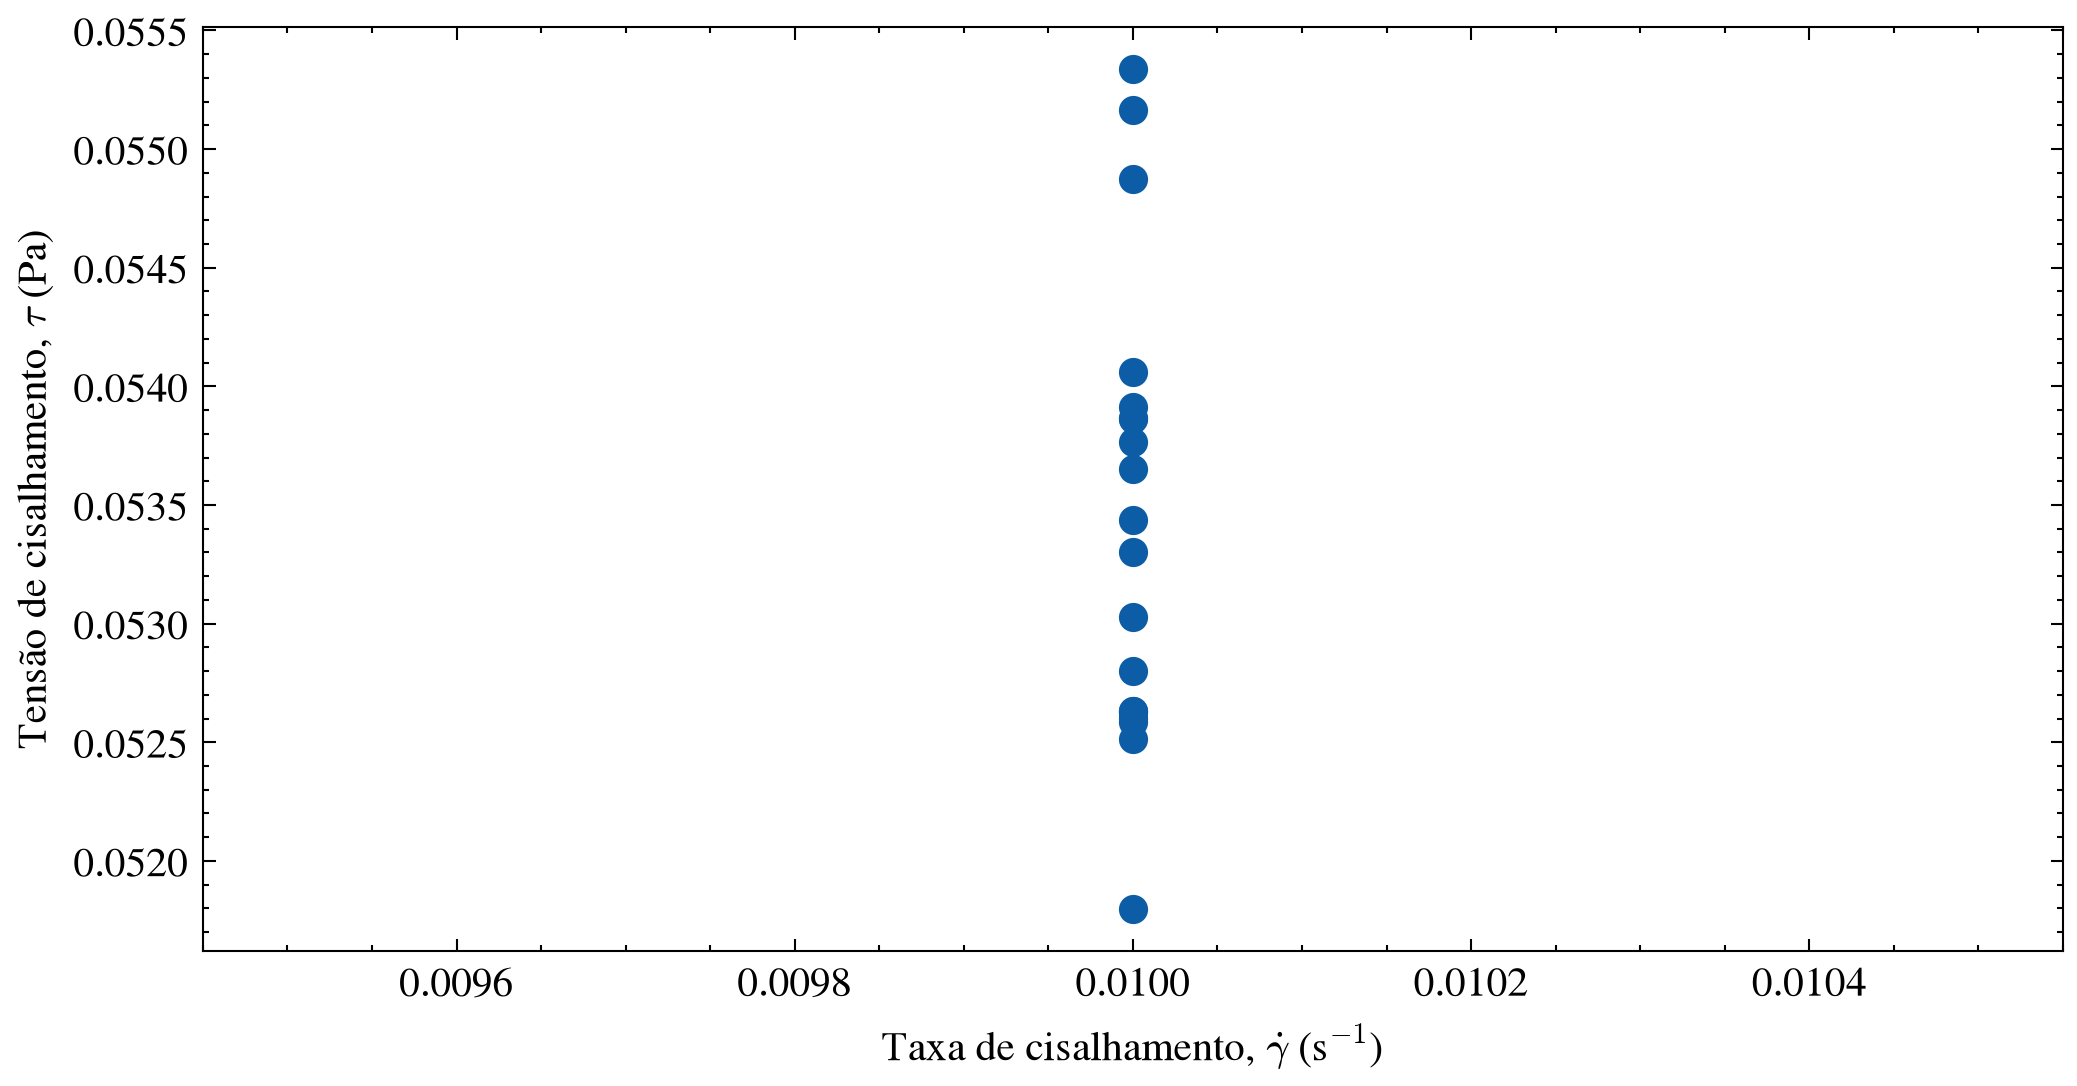

In [1061]:
last_20_seg1_guar = data_guar_1.tail(20)

plt.style.use(["science", "no-latex"])

plt.figure(figsize=(8, 4), dpi=300)
plt.plot(last_20_seg1_guar["γ̇ in 1/s"], last_20_seg1_guar["τ in Pa"], "o")
plt.xlabel(r"Taxa de cisalhamento, $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.legend()
plt.show()


In [1062]:
# Cálculo de média e desvio padrão

tau1_medio_guar = last_20_seg1_guar["τ in Pa"].mean()
tau1_std = last_20_seg1_guar["τ in Pa"].std()

display(Math(rf"\tau = {tau1_medio_guar:.4g} \pm {tau1_std:.2g}\ \mathrm{{Pa}}"))

<IPython.core.display.Math object>

In [1063]:
# Segundo segmento e guar

data_guar_2 = pd.read_excel("guar_seg_2.xlsx")
data_guar_2.head()

,SegIndex,t in s,t_seg in s,M in µN·m,Ω in rad/s,M in N.m,τ in Pa,γ̇ in 1/s,γ,seg
0,2|1,421.796051,1.002045,2.895357,0.003457,0.000003,0.257946,0.099,0.099202,2
1,2|2,422.796082,2.002075,3.403834,0.003486,0.000003,0.303246,0.100,0.200208,2
2,2|3,423.796143,3.002136,3.619337,0.003488,0.000004,0.322445,0.100,0.300214,2
3,2|4,424.796265,4.002258,3.740776,0.003487,0.000004,0.333264,0.100,0.400226,2
4,2|5,425.796204,5.002197,3.800209,0.003486,0.000004,0.338559,0.100,0.500220,2


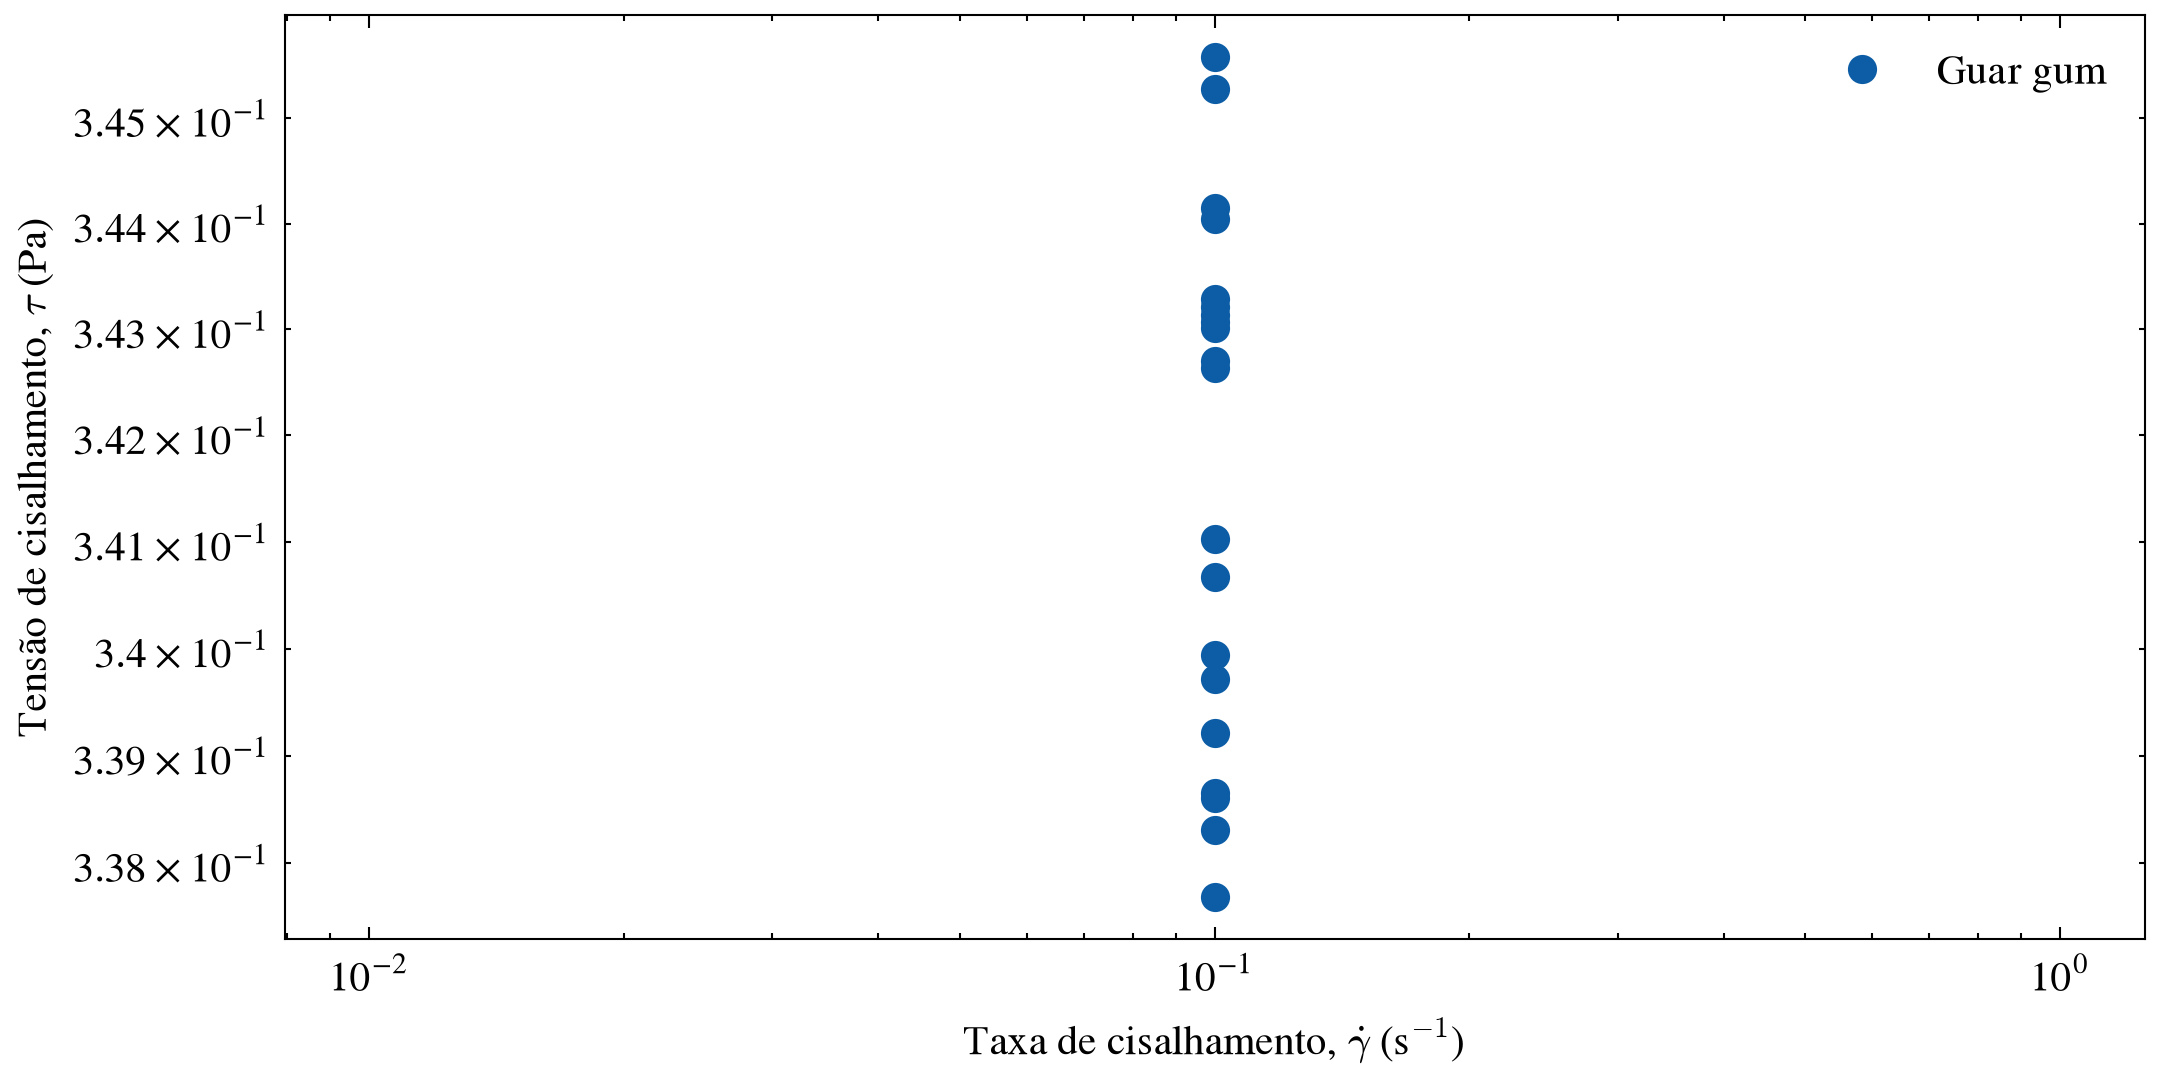

In [1064]:
last_20_seg2_guar = data_guar_2.tail(20)

plt.style.use(["science", "no-latex"])

plt.figure(figsize=(8, 4), dpi=300)
plt.loglog(last_20_seg2_guar["γ̇ in 1/s"], last_20_seg2_guar["τ in Pa"], "o", label="Guar gum")
plt.xlabel(r"Taxa de cisalhamento, $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.legend()
plt.show()

In [1065]:
tau2_medio_guar = last_20_seg2_guar["τ in Pa"].mean()
tau2_std = last_20_seg2_guar["τ in Pa"].std()

display(Math(rf"\tau = {tau2_medio_guar:.4g} \pm {tau2_std:.2g}\ \mathrm{{Pa}}"))

<IPython.core.display.Math object>

In [1066]:
data_guar_3 = pd.read_excel("guar_seg_3.xlsx")
data_guar_3.head()

,SegIndex,t in s,t_seg in s,M in µN·m,Ω in rad/s,M in N.m,τ in Pa,γ̇ in 1/s,γ,seg
0,3|1,722.070496,1.002014,26.052296,0.034713,0.000026,2.320990,0.994,0.996002,3
1,3|2,723.070496,2.002014,27.553753,0.034898,0.000028,2.454754,1.000,2.002014,3
2,3|3,724.070557,3.002075,27.273414,0.034916,0.000027,2.429779,1.000,3.002075,3
3,3|4,725.070740,4.002258,26.948086,0.034913,0.000027,2.400795,1.000,4.002258,3
4,3|5,726.070618,5.002136,26.748219,0.034910,0.000027,2.382989,1.000,5.002136,3


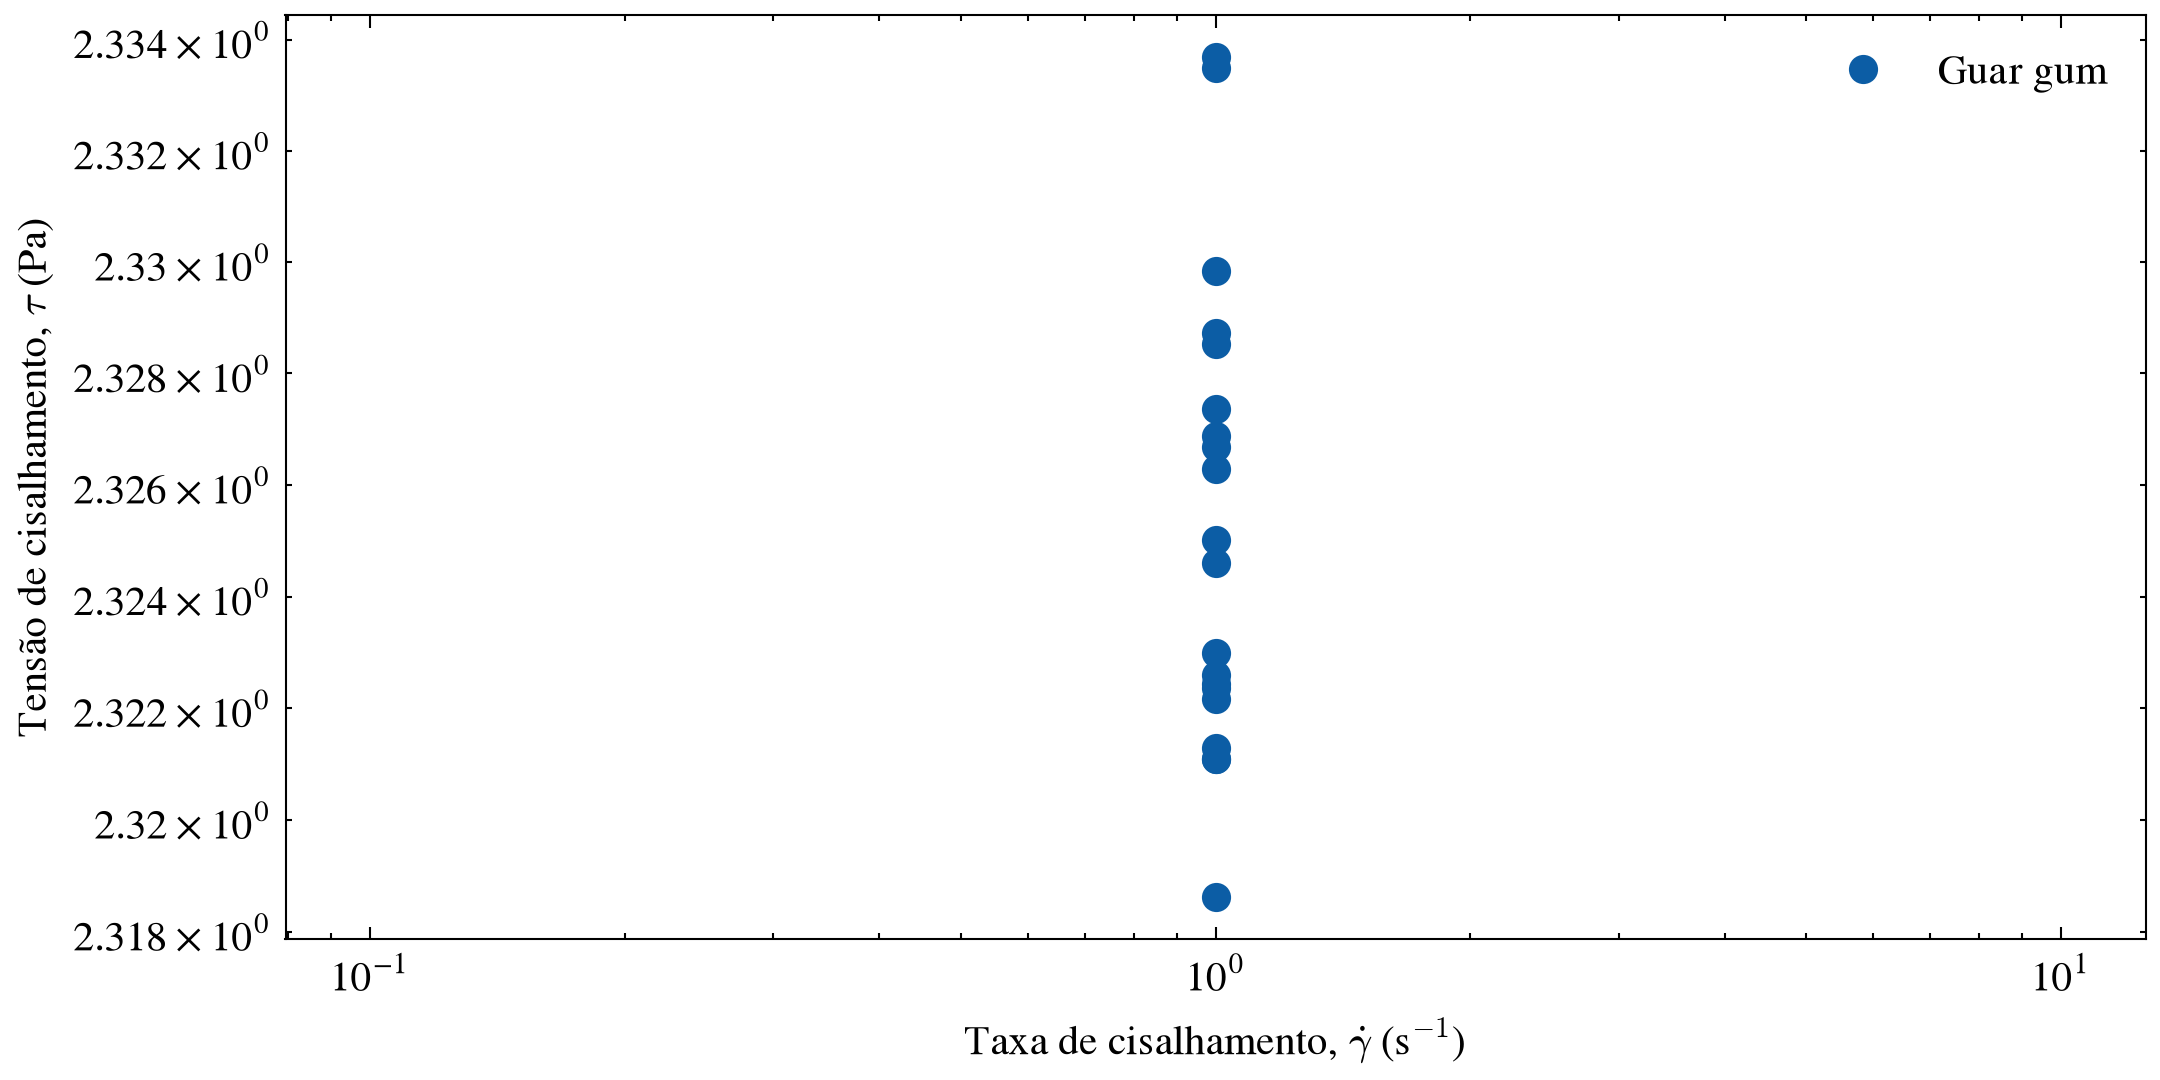

In [1067]:
last_20_seg3_guar = data_guar_3.tail(20)

plt.style.use(["science", "no-latex"])

plt.figure(figsize=(8, 4), dpi=300)
plt.loglog(last_20_seg3_guar["γ̇ in 1/s"], last_20_seg3_guar["τ in Pa"], "o", label="Guar gum")
plt.xlabel(r"Taxa de cisalhamento, $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.legend()
plt.show()

In [1068]:
tau3_medio_guar = last_20_seg3_guar["τ in Pa"].mean()
tau3_std = last_20_seg3_guar["τ in Pa"].std()

display(Math(rf"\tau = {tau3_medio_guar:.4g} \pm {tau3_std:.2g}\ \mathrm{{Pa}}"))

<IPython.core.display.Math object>

In [1069]:
# Quarto segmento

data_guar_4 = pd.read_excel("guar_seg_4.xlsx")
data_guar_4.head()

,SegIndex,t in s,t_seg in s,M in µN·m,Ω in rad/s,M in N.m,τ in Pa,γ̇ in 1/s,γ,seg
0,4|1,1022.451050,1.002136,99.782410,0.349166,0.0001,8.889580,10.003,10.024369,4
1,4|2,1023.450989,2.002075,99.991019,0.349038,0.0001,8.908165,9.999,20.018750,4
2,4|3,1024.450928,3.002014,99.846591,0.349060,0.0001,8.895298,10.000,30.020142,4
3,4|4,1025.451050,4.002136,99.891076,0.349041,0.0001,8.899261,9.999,40.017360,4
4,4|5,1026.451050,5.002136,99.773715,0.349036,0.0001,8.888805,9.999,50.016360,4


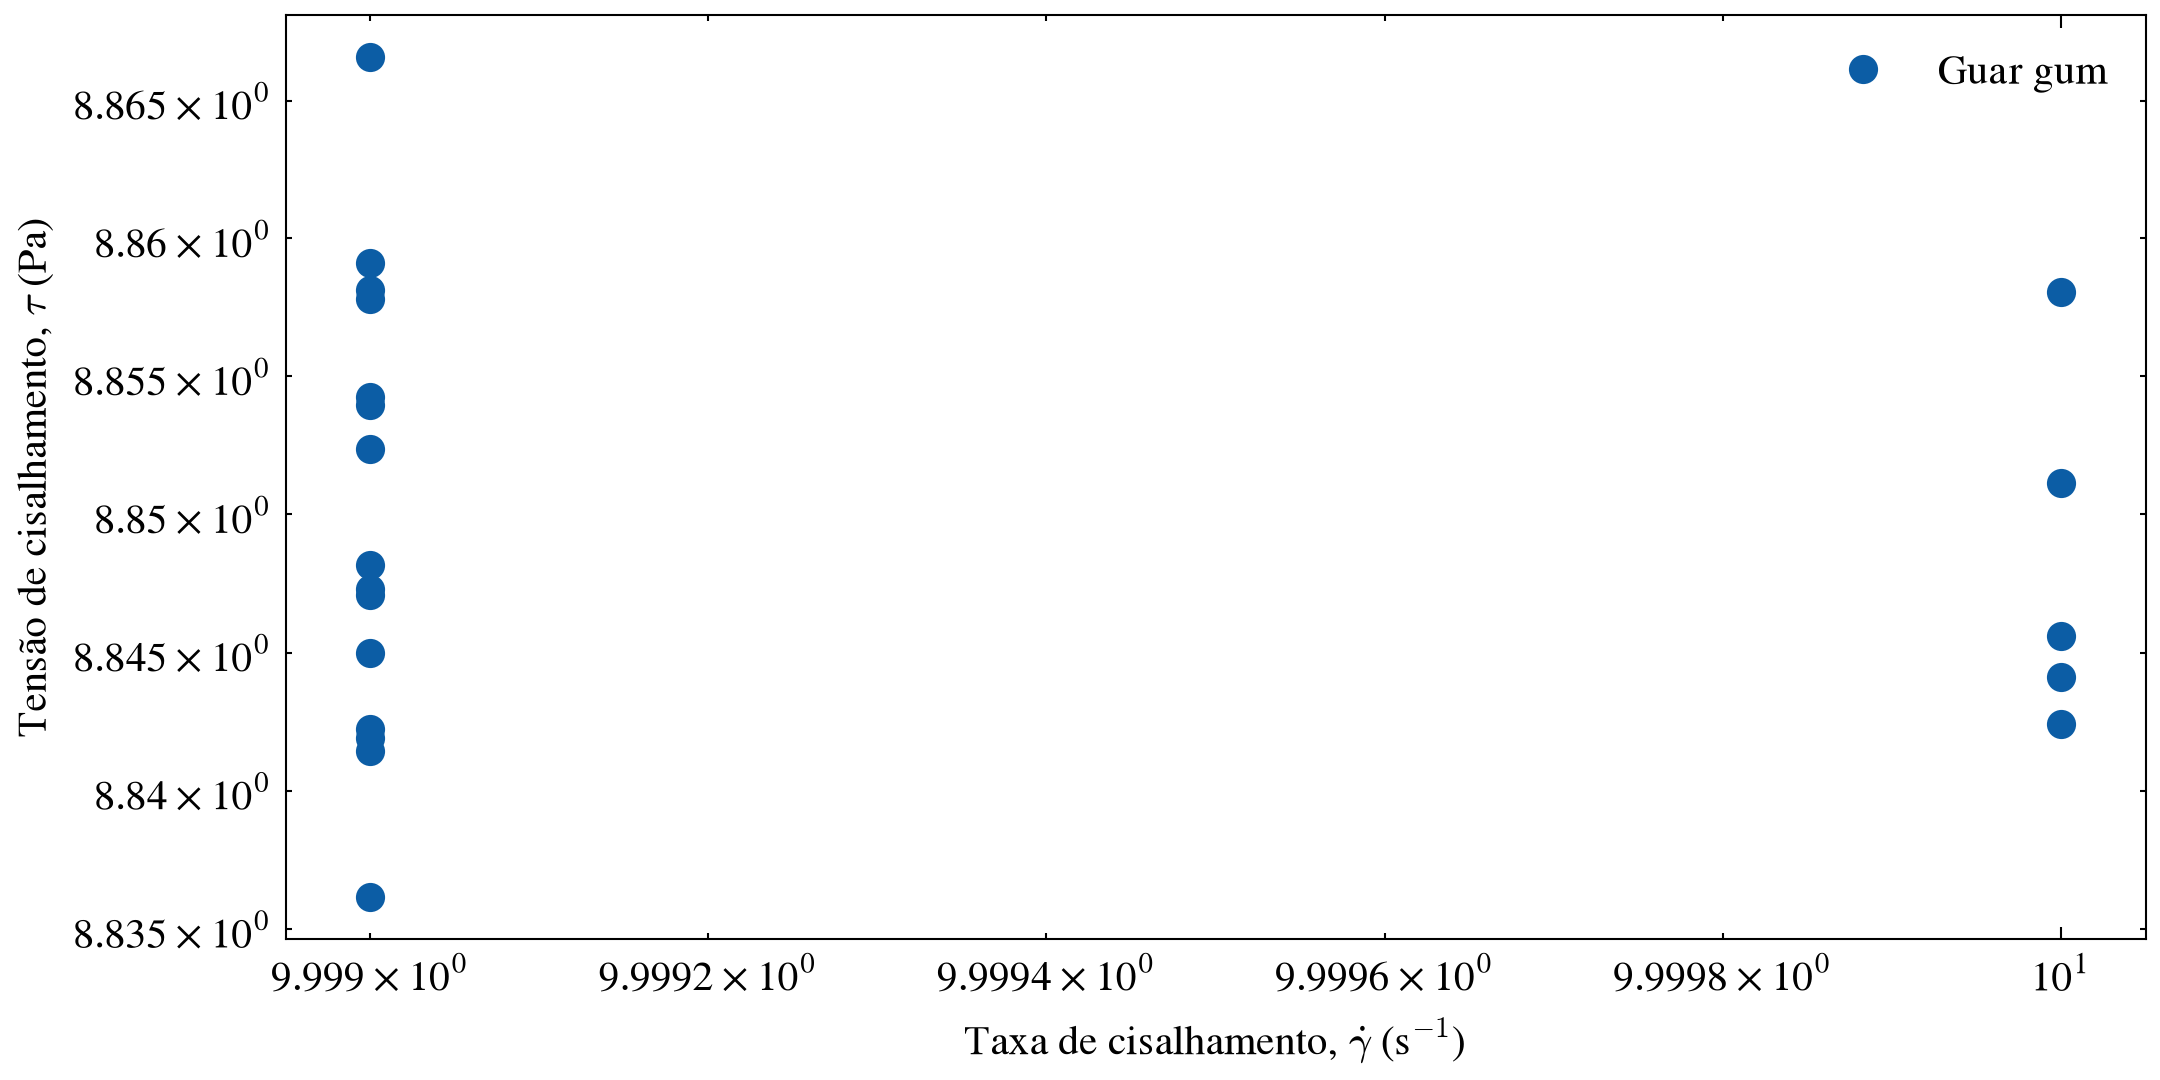

In [1070]:
last_20_seg4_guar = data_guar_4.tail(20)

plt.style.use(["science", "no-latex"])

plt.figure(figsize=(8, 4), dpi=300)
plt.loglog(last_20_seg4_guar["γ̇ in 1/s"], last_20_seg4_guar["τ in Pa"], "o", label="Guar gum")
plt.xlabel(r"Taxa de cisalhamento, $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.legend()
plt.show()

In [1071]:
tau4_medio_guar = last_20_seg4_guar["τ in Pa"].mean()
tau4_std = last_20_seg4_guar["τ in Pa"].std()

display(Math(rf"\tau = {tau4_medio_guar:.4g} \pm {tau4_std:.2g}\ \mathrm{{Pa}}"))

<IPython.core.display.Math object>

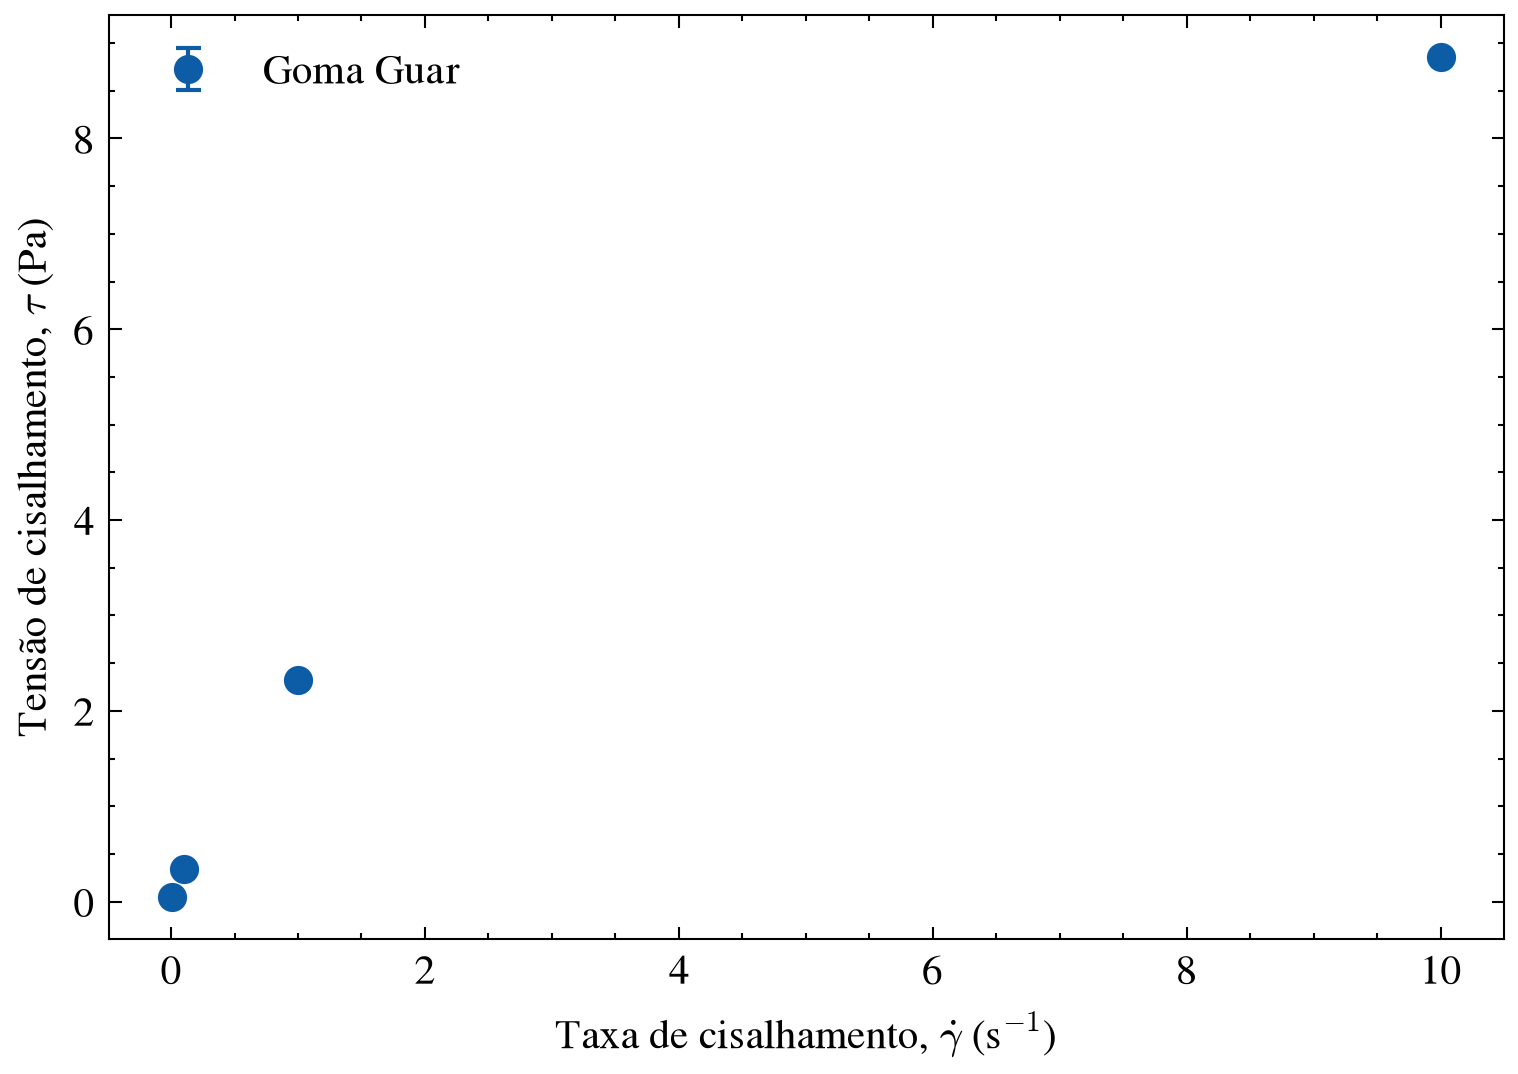

In [1072]:
plt.style.use(["science", "no-latex"])

gd = [
    last_20_seg1_guar["γ̇ in 1/s"].mean(),
    last_20_seg2_guar["γ̇ in 1/s"].mean(),
    last_20_seg3_guar["γ̇ in 1/s"].mean(),
    last_20_seg4_guar["γ̇ in 1/s"].mean(),
]

tau = [tau1_medio_guar, tau2_medio_guar, tau3_medio_guar, tau4_medio_guar]
tau_std = [tau1_std, tau2_std, tau3_std, tau4_std]

plt.figure(figsize=(6, 4), dpi=300)
plt.errorbar(gd, tau, yerr=tau_std, fmt="o", capsize=3, label="Goma Guar")
plt.xlabel(r"Taxa de cisalhamento, $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.legend()
plt.show()

Para descrever a curva acima, usar-se-á a seguinte lei de potência:

   $$ \tau = K \, \dot{\gamma}^n$$

Que aplicando logatimo em ambos os lados, tem-se


$$    \log {\tau} = n \log {\dot{\gamma}} + log{K}$$


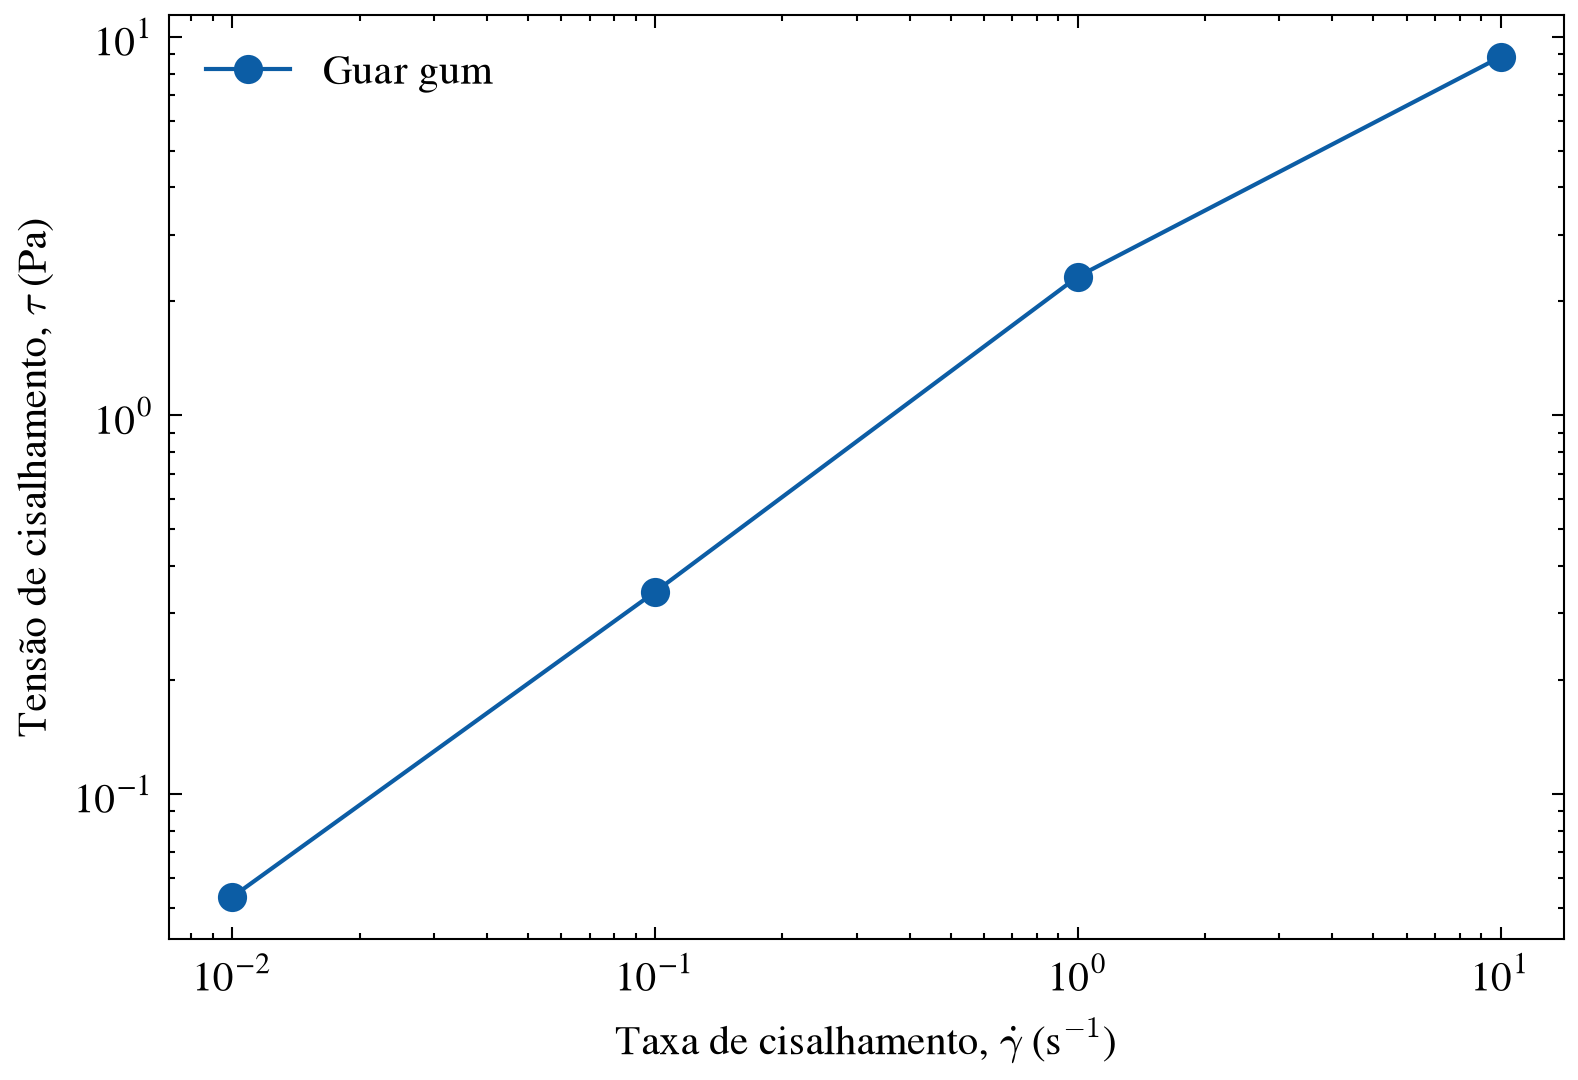

In [1073]:
plt.style.use(["science", "no-latex"])

gd = [
    last_20_seg1_guar["γ̇ in 1/s"].mean(),
    last_20_seg2_guar["γ̇ in 1/s"].mean(),
    last_20_seg3_guar["γ̇ in 1/s"].mean(),
    last_20_seg4_guar["γ̇ in 1/s"].mean(),
]

tau = [tau1_medio_guar, tau2_medio_guar, tau3_medio_guar, tau4_medio_guar]
tau_std = [tau1_std, tau2_std, tau3_std, tau4_std]

plt.figure(figsize=(6, 4), dpi=300)
plt.loglog(gd, tau, "o-", label="Guar gum")
plt.xlabel(r"Taxa de cisalhamento, $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.legend()
plt.show()

In [1074]:
# Obtendo a reta que melhor se ajusta aos dados

gd = np.array(gd)
tau = np.array(tau)

n, logK = np.polyfit(np.log10(gd), np.log10(tau), 1)  # Sintaxe geral do comando polyfit(x,y,grau)
K = 10**logK

# classificação pelo índice de comportamento n

if n < 1:
    tipo = "pseudoplástico (shear thinning)"
elif n > 1:
    tipo = "dilatante (shear thickening)"
else:
    tipo = "newtoniano"

display(Math(
    rf"\tau = K\,\dot{{\gamma}}^{{n}}, \quad "
    rf"n = {n:.3f}, \quad "
    rf"K = {K:.3g}\ \mathrm{{Pa\cdot s^{{{n:.2f}}}}}"
))
display(Markdown(f"Como $n = {n:.3f}$, o fluido é **{tipo}**."))

<IPython.core.display.Math object>

Como $n = 0.749$, o fluido é **pseudoplástico (shear thinning)**.

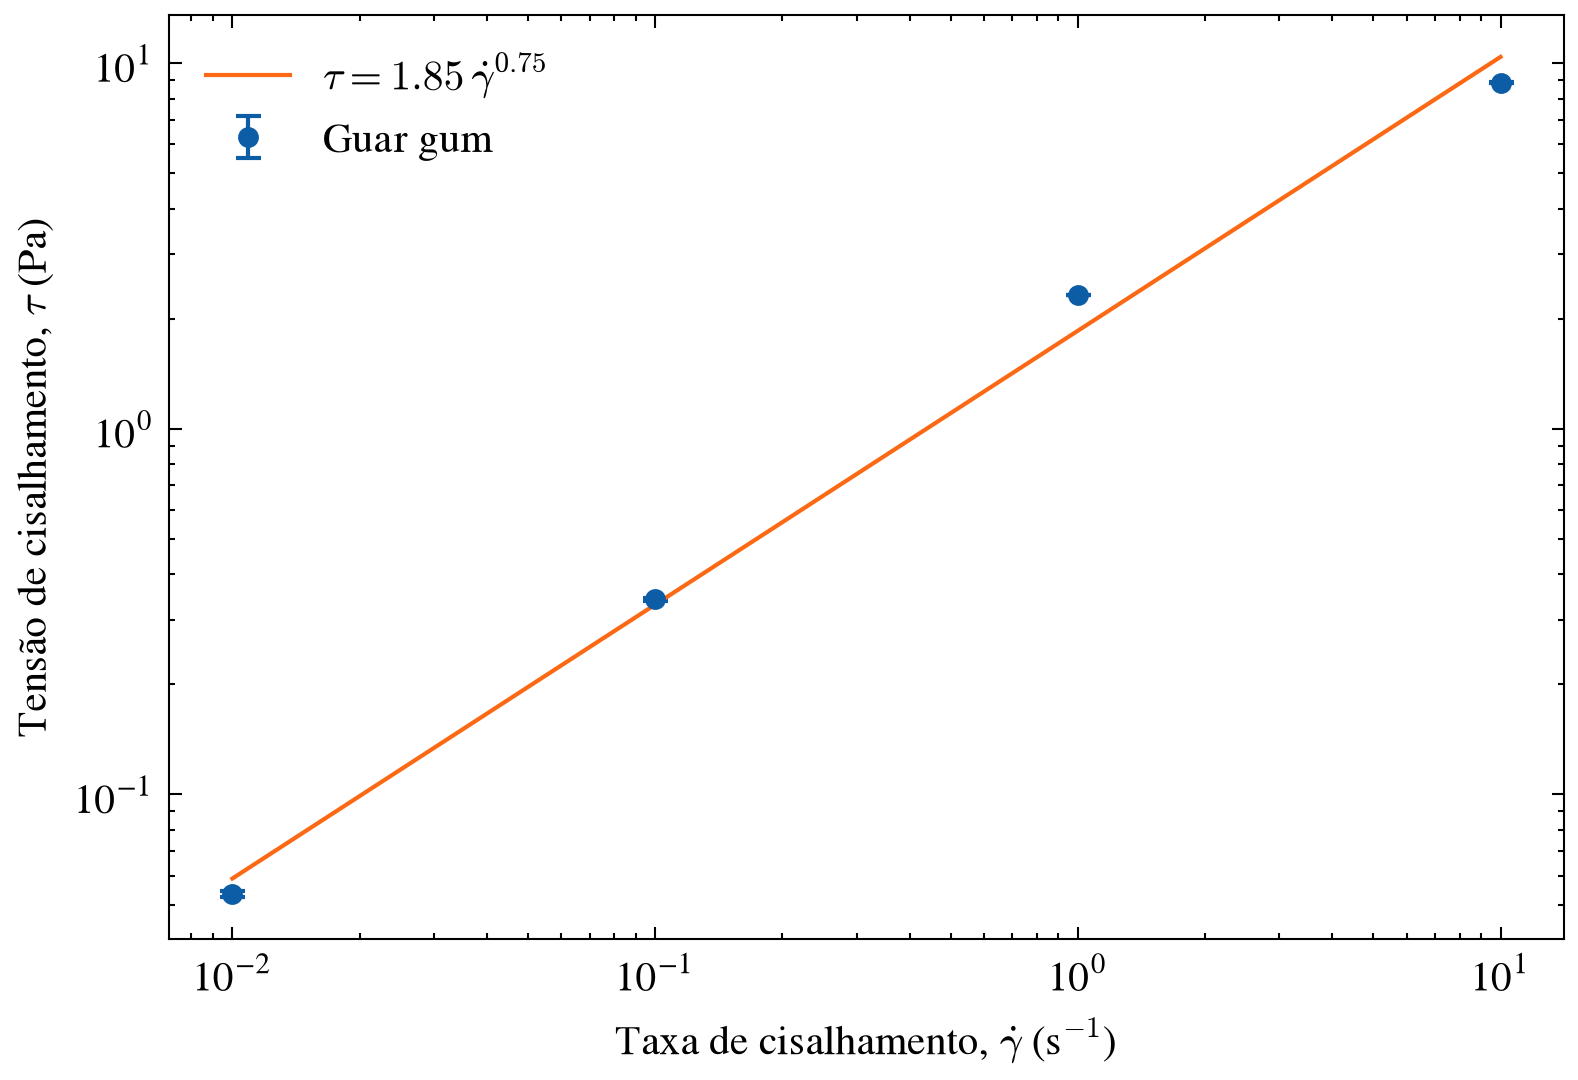

In [1075]:
gd_fit = np.logspace(np.log10(gd.min()), np.log10(gd.max()), 100)
tau_fit = K * gd_fit**n

plt.figure(figsize=(6, 4), dpi=300)
plt.errorbar(gd, tau, yerr=tau_std, fmt="o", markersize=4, capsize=3, label="Guar gum")
plt.plot(gd_fit, tau_fit, "-", color='#fc6914', label=rf"$\tau = {K:.3g}\,\dot{{\gamma}}^{{{n:.2f}}}$")
plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"Taxa de cisalhamento, $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.legend()
plt.show()

In [1076]:
log_tau_pred = n * np.log10(gd) + logK
ss_res = np.sum((np.log10(tau) - log_tau_pred)**2)
ss_tot = np.sum((np.log10(tau) - np.log10(tau).mean())**2)
r2 = 1 - ss_res / ss_tot
print(f"R² = {r2:.4f}")

R² = 0.9941


A viscosidade aparente:

$$\eta = \frac{\tau}{\dot{\gamma}}$$

Assim

$$\eta \, \dot{\gamma} = K \, \dot{\gamma}^n$$

$$\eta = K \, \dot{\gamma}^{n-1}$$

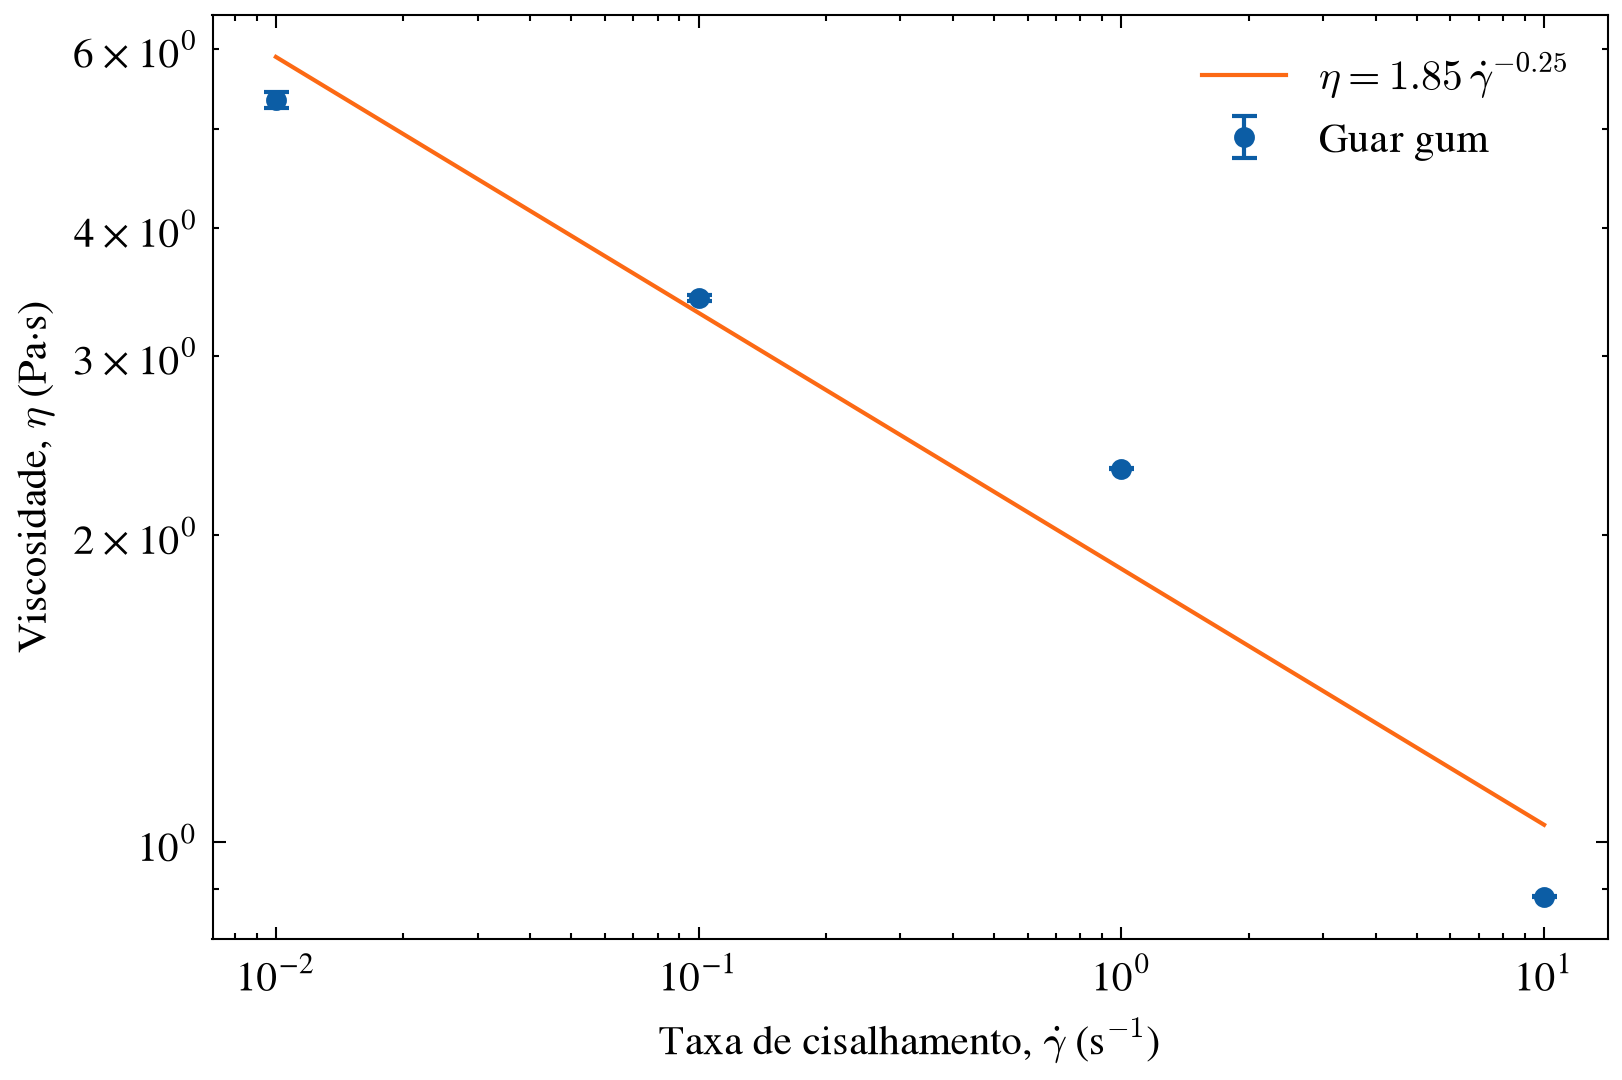

In [1077]:
eta = tau / gd
eta_std = tau_std / gd
eta_fit = K * gd_fit**(n - 1)

plt.figure(figsize=(6, 4), dpi=300)
plt.errorbar(gd, eta, yerr=eta_std, fmt="o", markersize=4, capsize=3, label="Guar gum")
plt.plot(gd_fit, eta_fit, "-", color='#fc6914', label=rf"$\eta = {K:.3g}\,\dot{{\gamma}}^{{{n-1:.2f}}}$")
plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"Taxa de cisalhamento, $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel(r"Viscosidade, $\eta$ (Pa$\cdot$s)")
plt.legend()
plt.show()

# 2.0 Goma Xantana

In [1078]:
xantan = pd.read_excel(data, sheet_name=1)
xantan.head()

,SegIndex,t in s,t_seg in s,M in µN·m,Ω in rad/s
0,1|1,121.565399,1.002052,0.681740,0.000311
1,1|2,122.565437,2.002090,1.625570,0.000318
2,1|3,123.565437,3.002090,2.499469,0.000322
3,1|4,124.565491,4.002144,3.278108,0.000324
4,1|5,125.565544,5.002197,4.010273,0.000326


In [1079]:
xantan["M in N.m"] = xantan["M in µN·m"] * 10**-6
xantan["τ in Pa"] = (3 * xantan["M in N.m"]) / (2 * np.pi * (dic["R"]**3))
xantan["γ̇ in 1/s"] = (xantan["Ω in rad/s"] / dic["beta"])
xantan["γ"] = xantan["γ̇ in 1/s"] * xantan["t_seg in s"]
xantan.head()

,SegIndex,t in s,t_seg in s,M in µN·m,Ω in rad/s,M in N.m,τ in Pa,γ̇ in 1/s,γ
0,1|1,121.565399,1.002052,0.681740,0.000311,6.817396e-07,0.060736,0.008924,0.008942
1,1|2,122.565437,2.002090,1.625570,0.000318,1.625570e-06,0.144821,0.009112,0.018243
2,1|3,123.565437,3.002090,2.499469,0.000322,2.499469e-06,0.222677,0.009225,0.027694
3,1|4,124.565491,4.002144,3.278108,0.000324,3.278108e-06,0.292045,0.009275,0.037119
4,1|5,125.565544,5.002197,4.010273,0.000326,4.010273e-06,0.357274,0.009348,0.046759


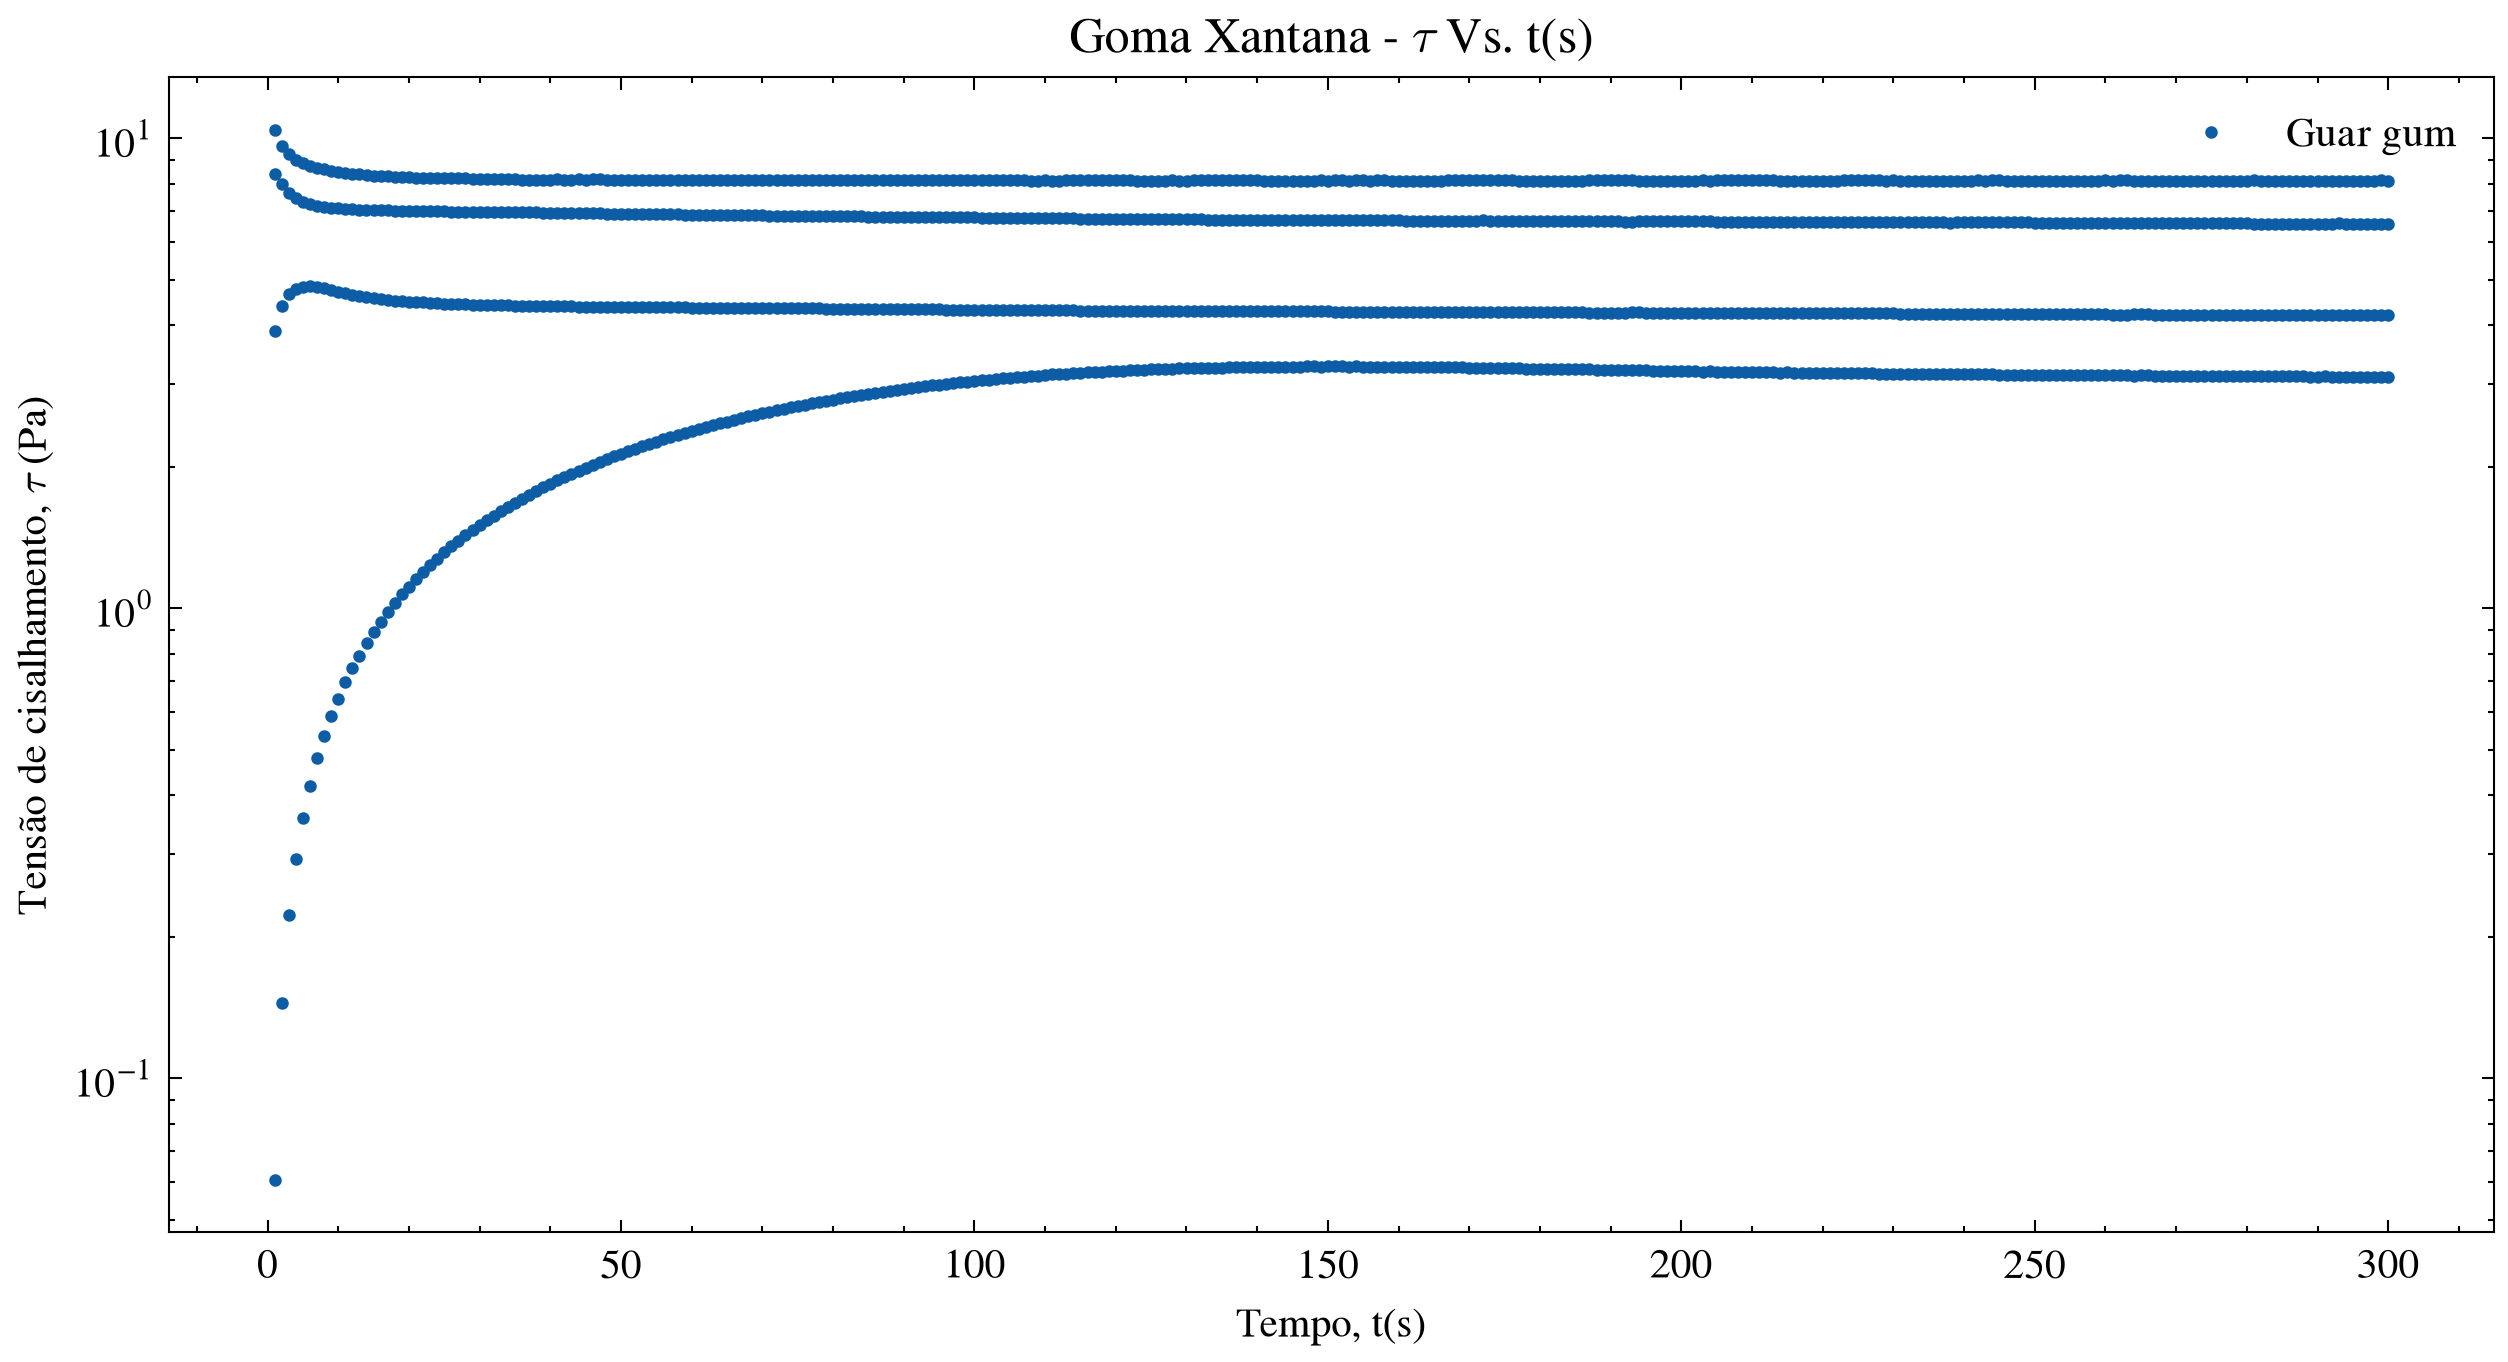

In [1080]:
plt.style.use(["science", "no-latex"])

plt.figure(figsize=(10,5), dpi=300)
plt.semilogy(xantan["t_seg in s"], xantan["τ in Pa"], "o", markersize=2, label="Guar gum")
plt.xlabel(r"Tempo, t(s)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.title(r"Goma Xantana - $\tau$ Vs. t(s)")
plt.legend()
plt.show()

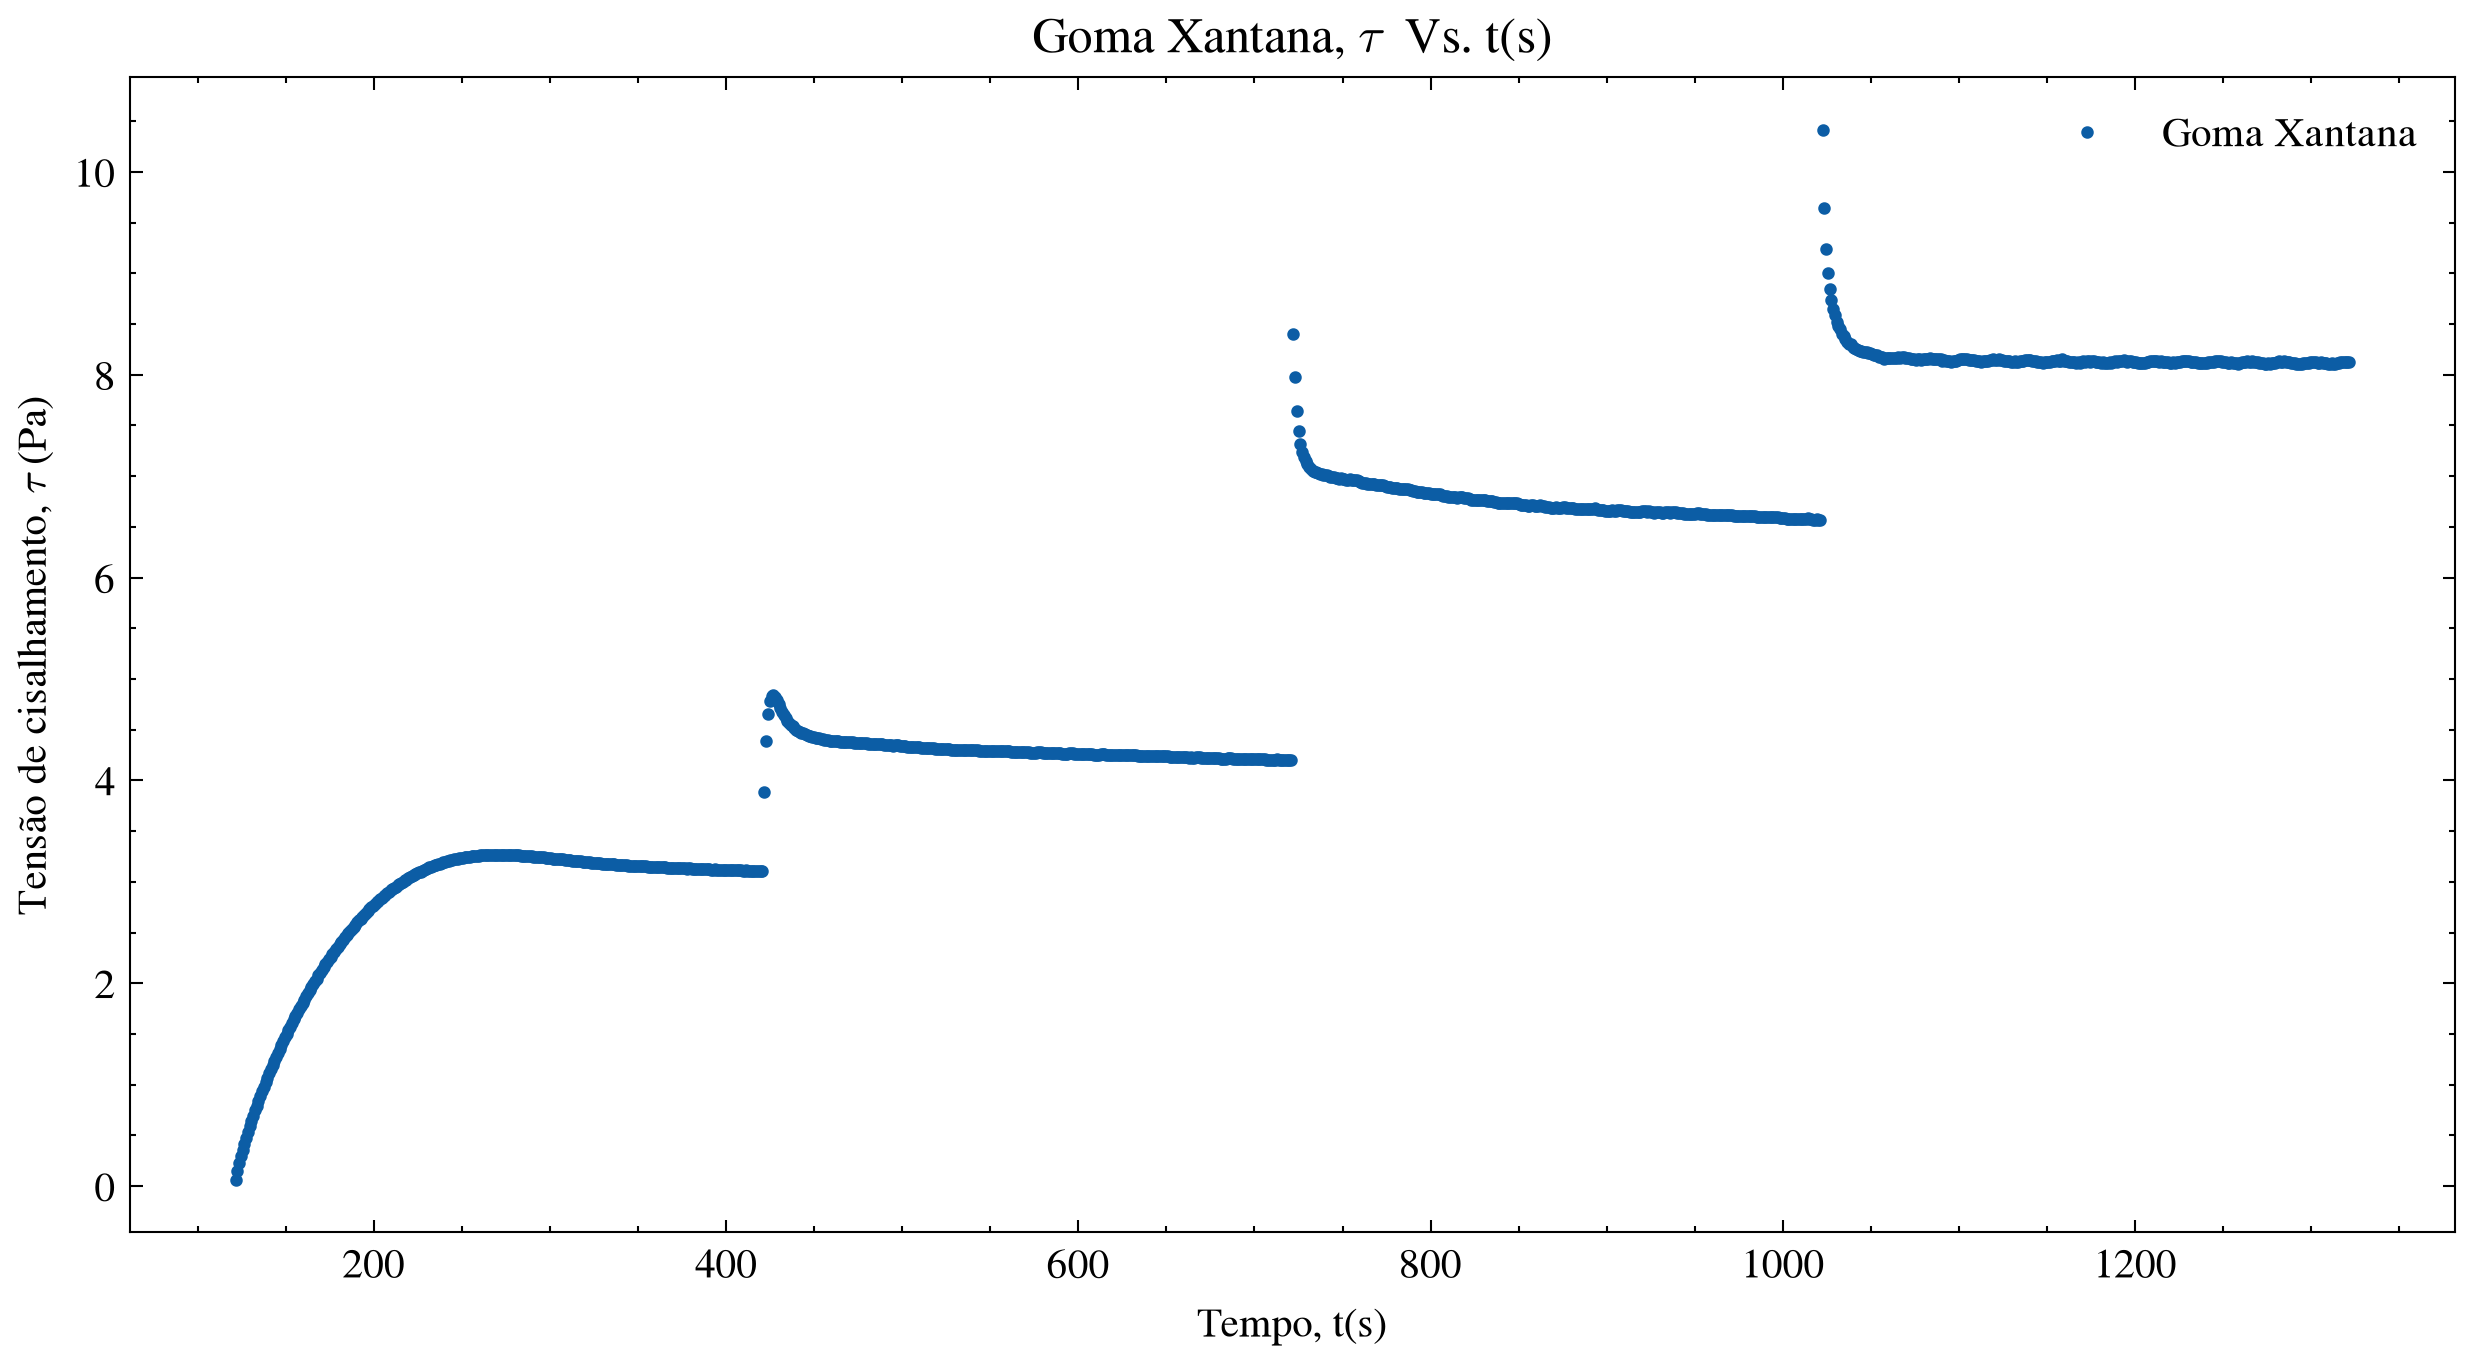

In [1081]:
plt.style.use(["science", "no-latex"])

plt.figure(figsize=(10,5), dpi=300)
plt.plot(xantan["t in s"], xantan["τ in Pa"], "o", markersize=2, label="Goma Xantana")
plt.xlabel(r"Tempo, t(s)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.title(r"Goma Xantana, $\tau$  Vs. t(s)")
plt.legend()
plt.show()

In [1082]:
# Separando as planilhas pela taxa de cisalhamento

xantan["seg"] = xantan["SegIndex"].str.split("|").str[0].astype(int)

for s, g in xantan.groupby("seg"):
    g.to_excel(f"xantan_seg_{s}.xlsx", index=False)

C:\Users\abner.pereira\AppData\Local\Temp\ipykernel_20688\2909110235.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


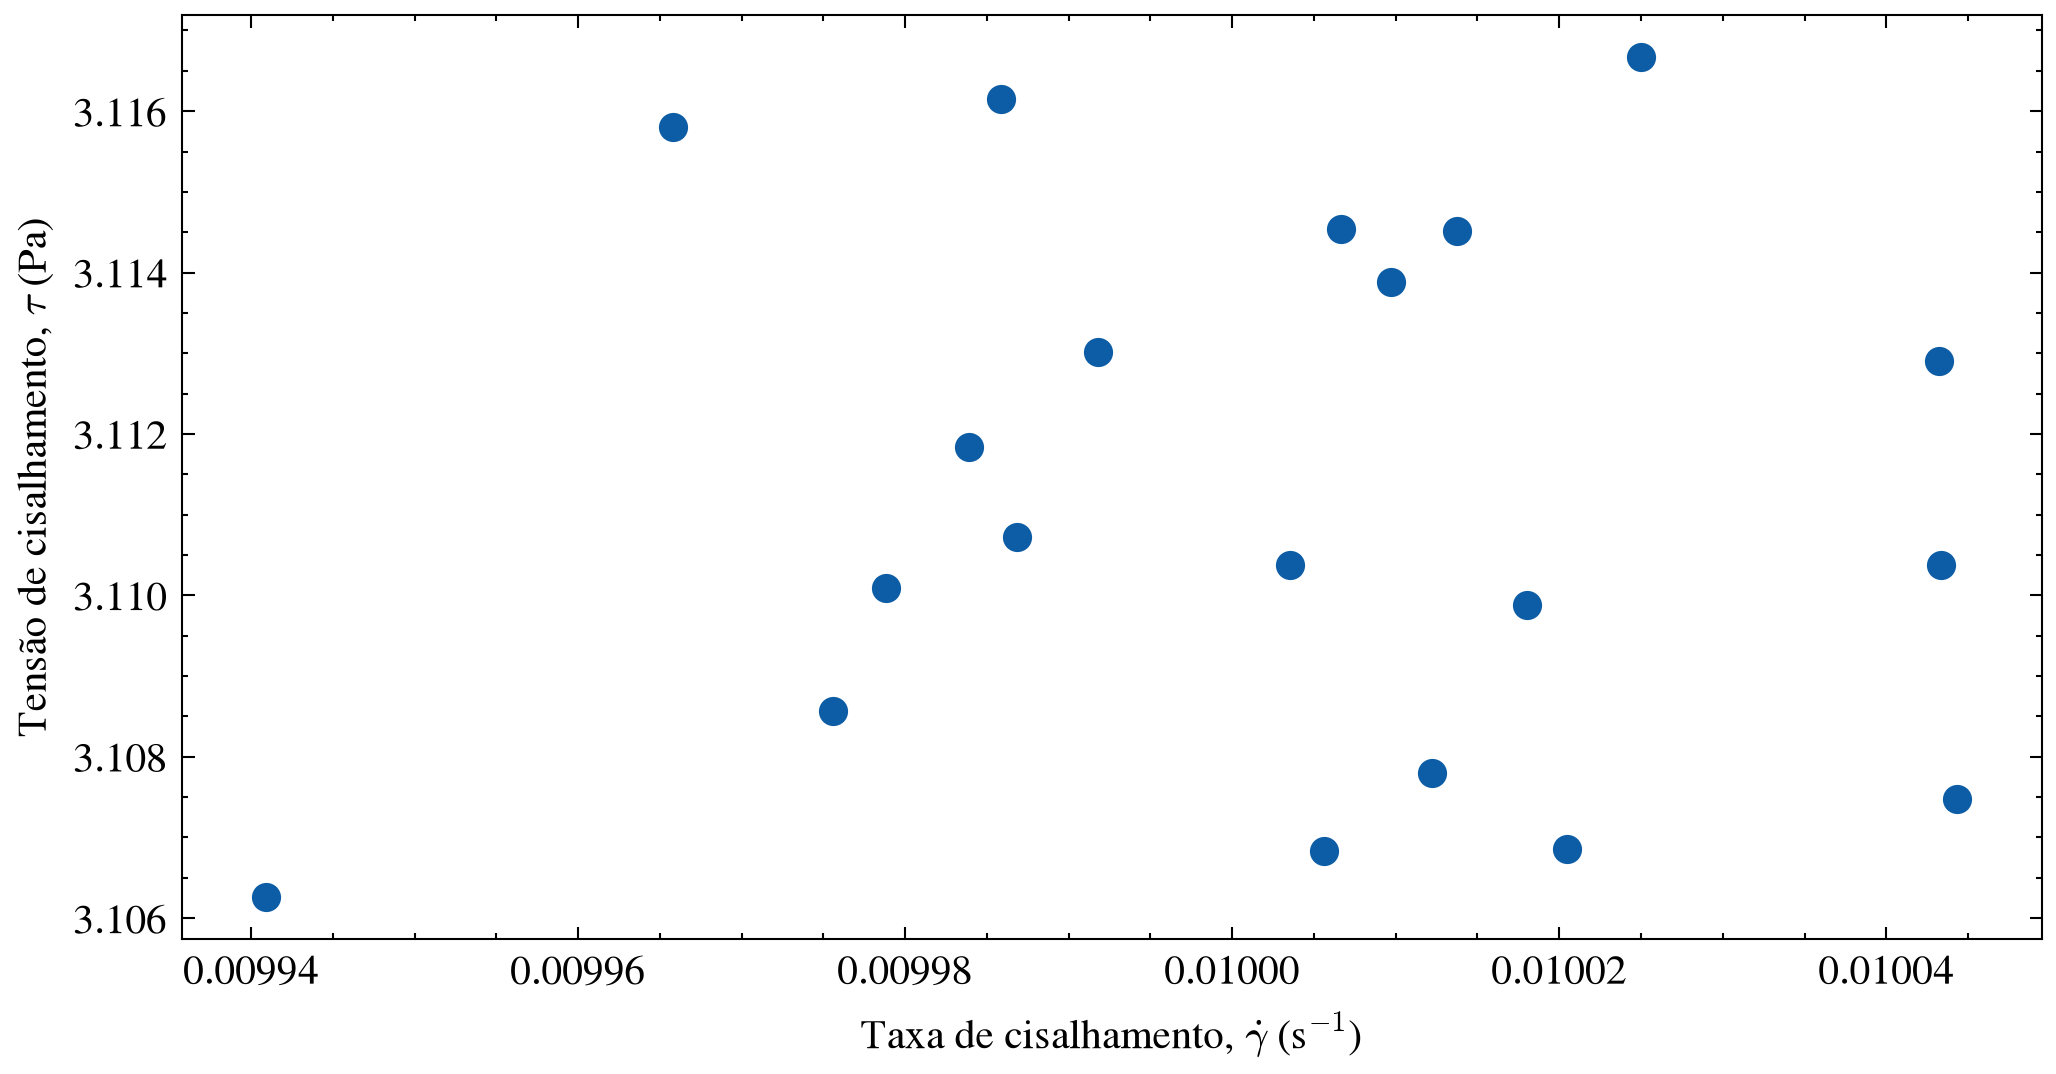

In [1083]:
data_xantan_1 = pd.read_excel("xantan_seg_1.xlsx")

last_20_seg1_xantan = data_xantan_1.tail(20)

plt.figure(figsize=(8, 4), dpi=300)
plt.plot(last_20_seg1_xantan["γ̇ in 1/s"], last_20_seg1_xantan["τ in Pa"], "o")
plt.xlabel(r"Taxa de cisalhamento, $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.legend()
plt.show()


In [1084]:
tau1_medio_xantan = last_20_seg1_xantan["τ in Pa"].mean()
tau1_std_xantan = last_20_seg1_xantan["τ in Pa"].std()

display(Math(rf"\tau = {tau1_medio_xantan:.4g} \pm {tau1_std_xantan:.2g}\ \mathrm{{Pa}}"))


<IPython.core.display.Math object>

C:\Users\abner.pereira\AppData\Local\Temp\ipykernel_20688\1747929576.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


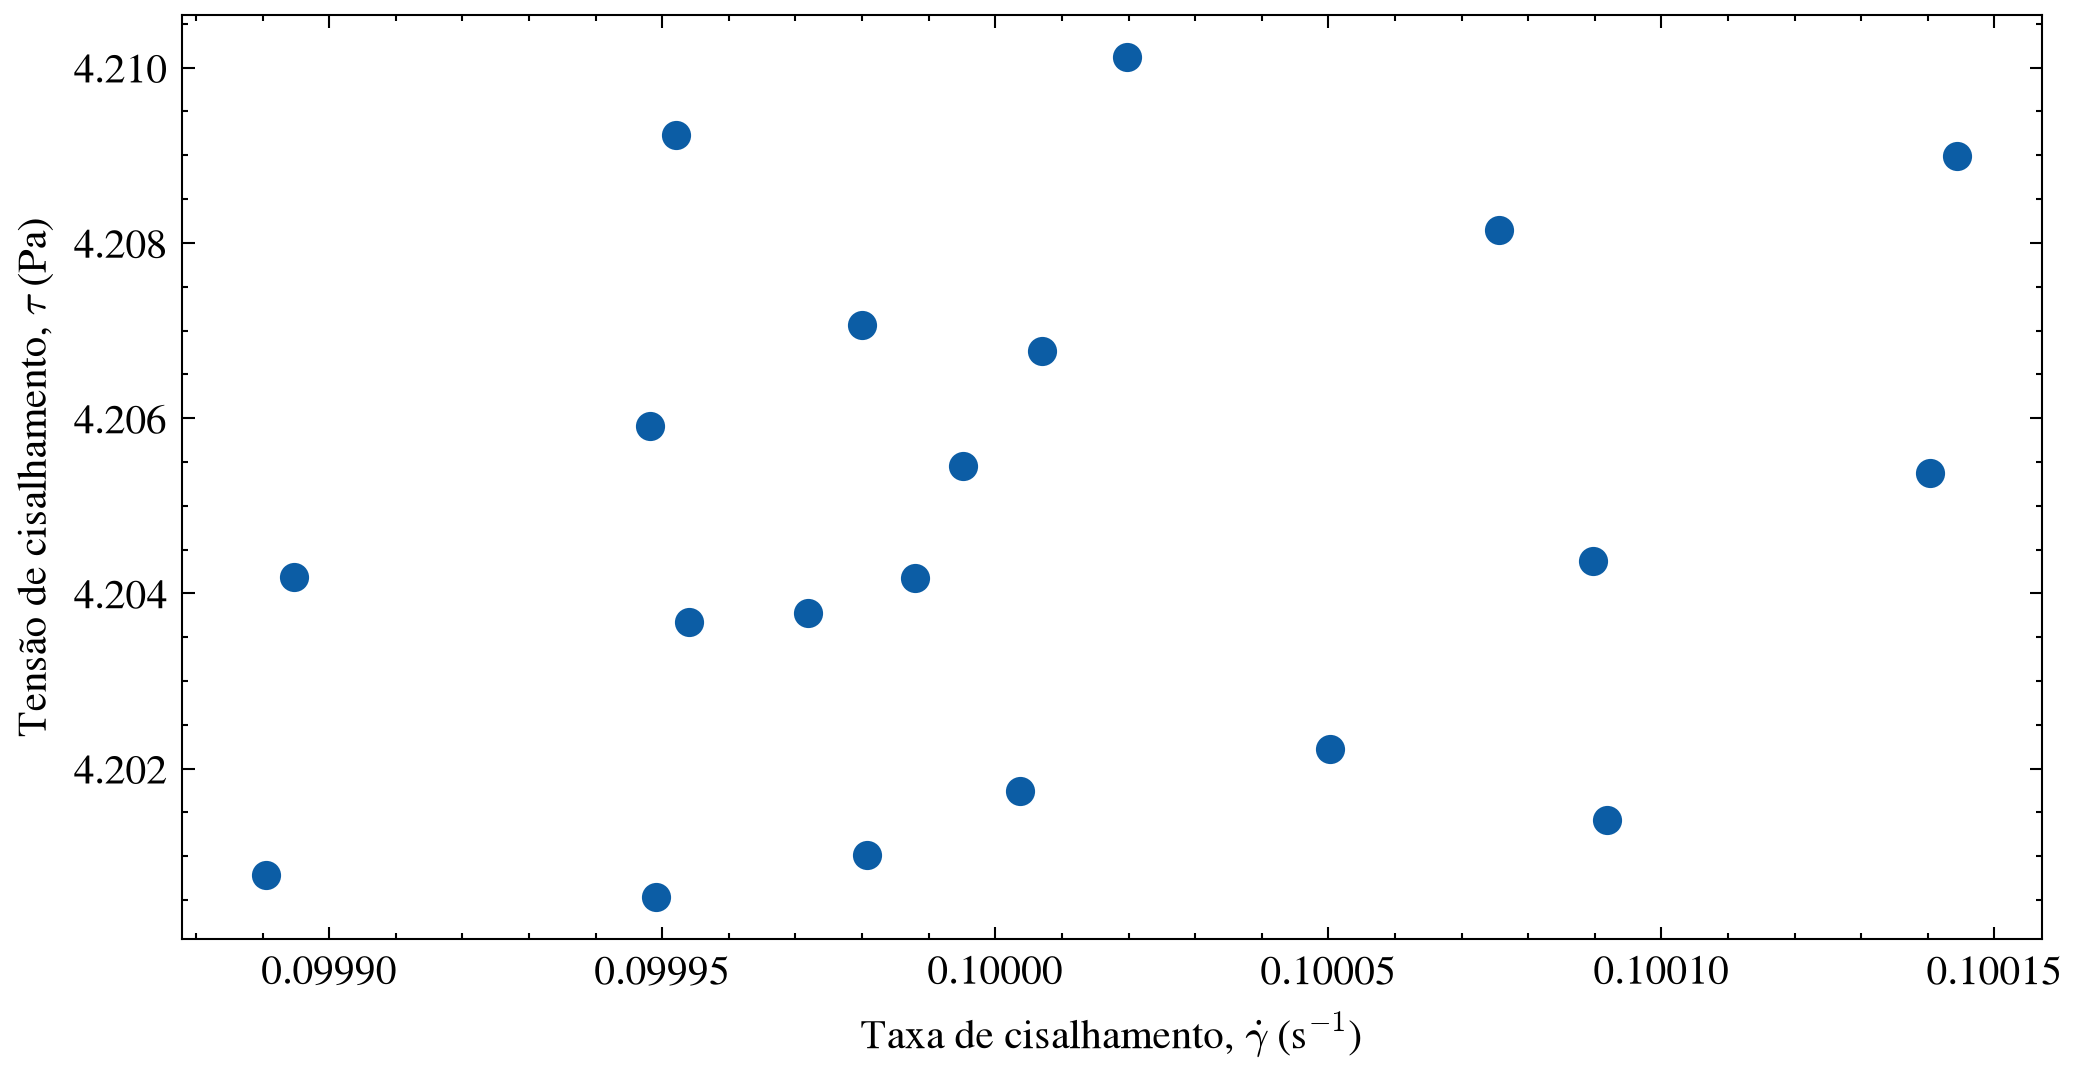

In [1085]:
# Segundo segmento da goma xantana

data_xantan_2 = pd.read_excel("xantan_seg_2.xlsx")

last_20_seg2_xantan = data_xantan_2.tail(20)

plt.figure(figsize=(8, 4), dpi=300)
plt.plot(last_20_seg2_xantan["γ̇ in 1/s"], last_20_seg2_xantan["τ in Pa"], "o")
plt.xlabel(r"Taxa de cisalhamento, $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.legend()
plt.show()



In [1086]:
tau2_medio_xantan = last_20_seg2_xantan["τ in Pa"].mean()
tau2_std_xantan = last_20_seg2_xantan["τ in Pa"].std()

display(Math(rf"\tau = {tau2_medio_xantan:.4g} \pm {tau2_std_xantan:.2g}\ \mathrm{{Pa}}"))

<IPython.core.display.Math object>

C:\Users\abner.pereira\AppData\Local\Temp\ipykernel_20688\2608359862.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


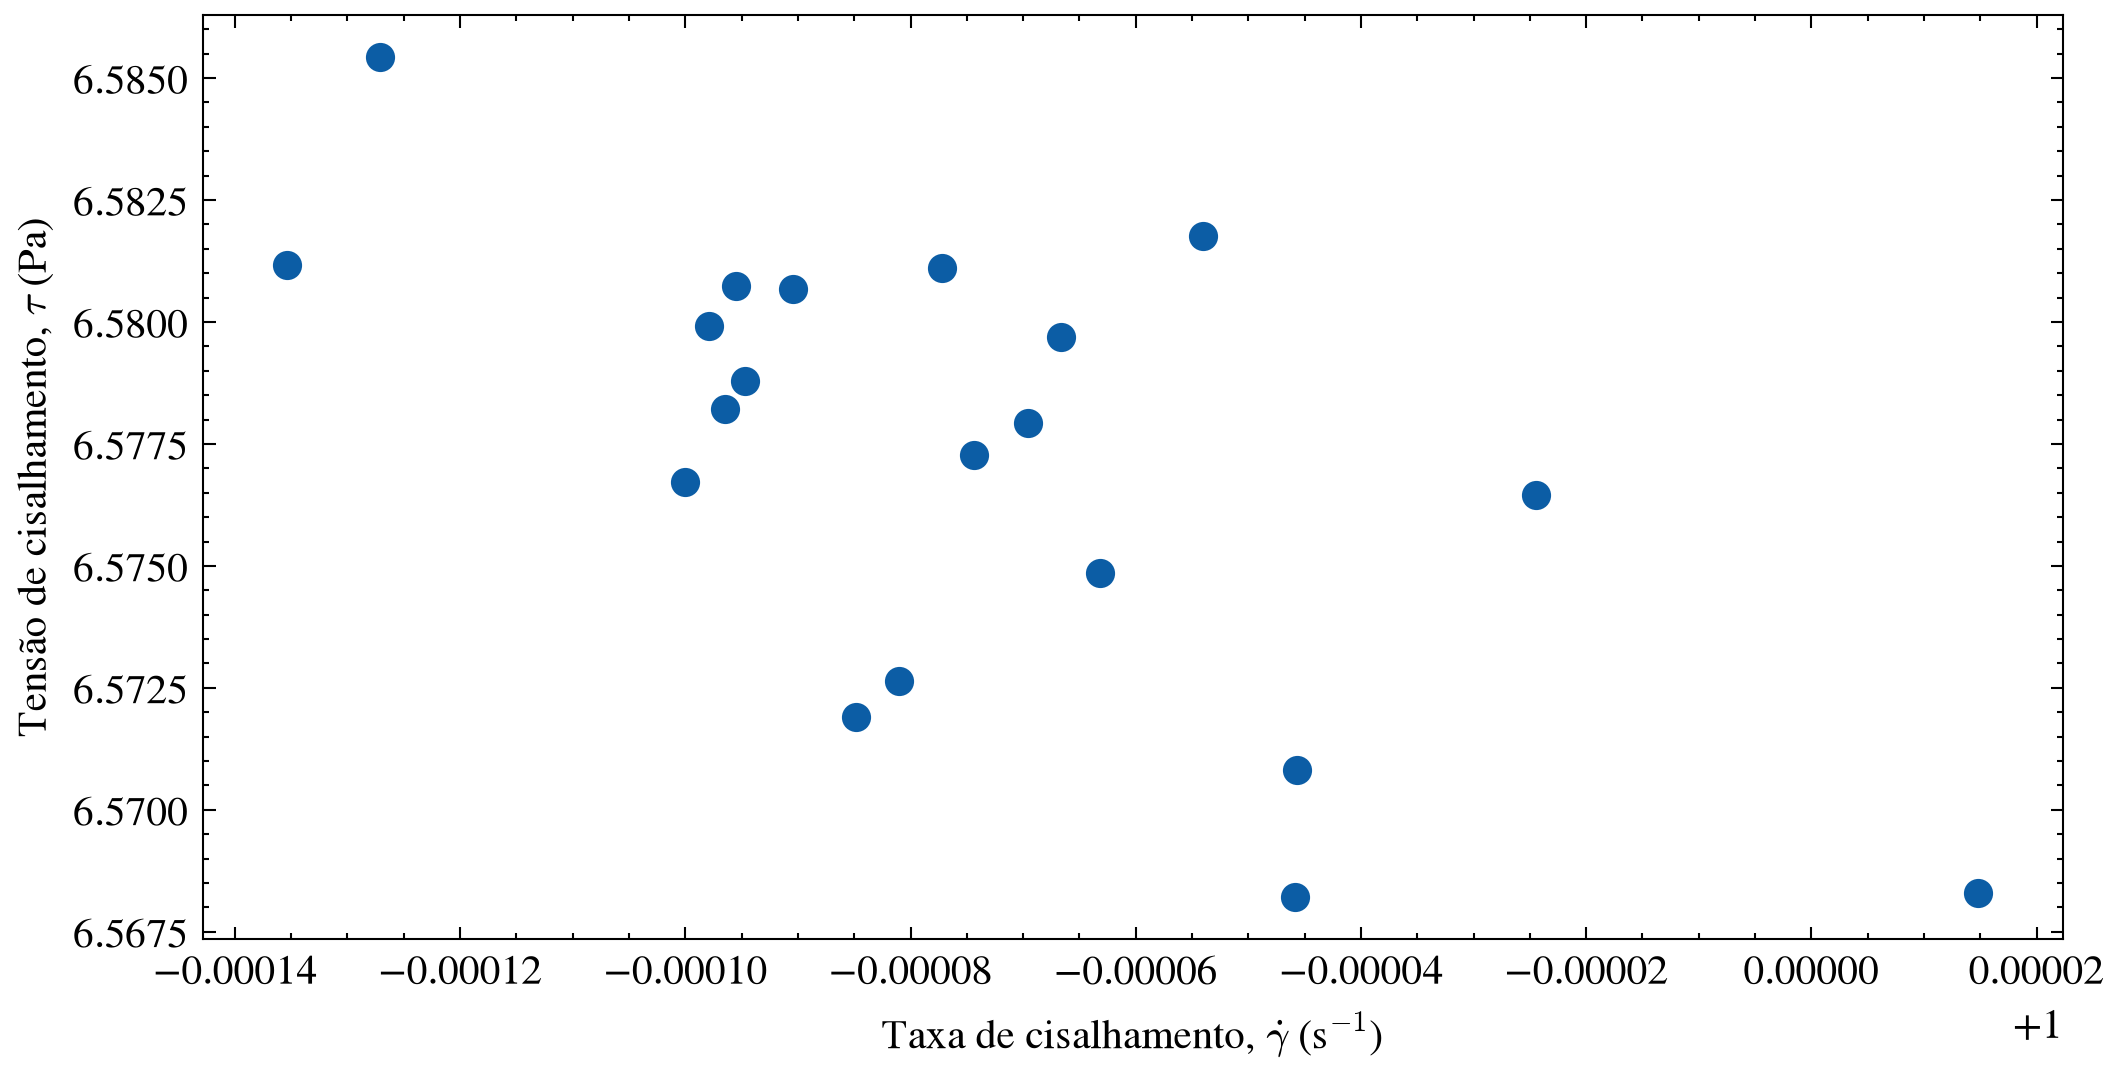

In [1087]:
# Terceiro segmento da goma xantana

data_xantan_3 = pd.read_excel("xantan_seg_3.xlsx")

last_20_seg3_xantan = data_xantan_3.tail(20)

plt.figure(figsize=(8, 4), dpi=300)
plt.plot(last_20_seg3_xantan["γ̇ in 1/s"], last_20_seg3_xantan["τ in Pa"], "o")
plt.xlabel(r"Taxa de cisalhamento, $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.legend()
plt.show()

In [1088]:
tau3_medio_xantan = last_20_seg3_xantan["τ in Pa"].mean()
tau3_std_xantan = last_20_seg3_xantan["τ in Pa"].std()

display(Math(rf"\tau = {tau3_medio_xantan:.4g} \pm {tau3_std_xantan:.2g}\ \mathrm{{Pa}}"))

<IPython.core.display.Math object>

C:\Users\abner.pereira\AppData\Local\Temp\ipykernel_20688\3236271389.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


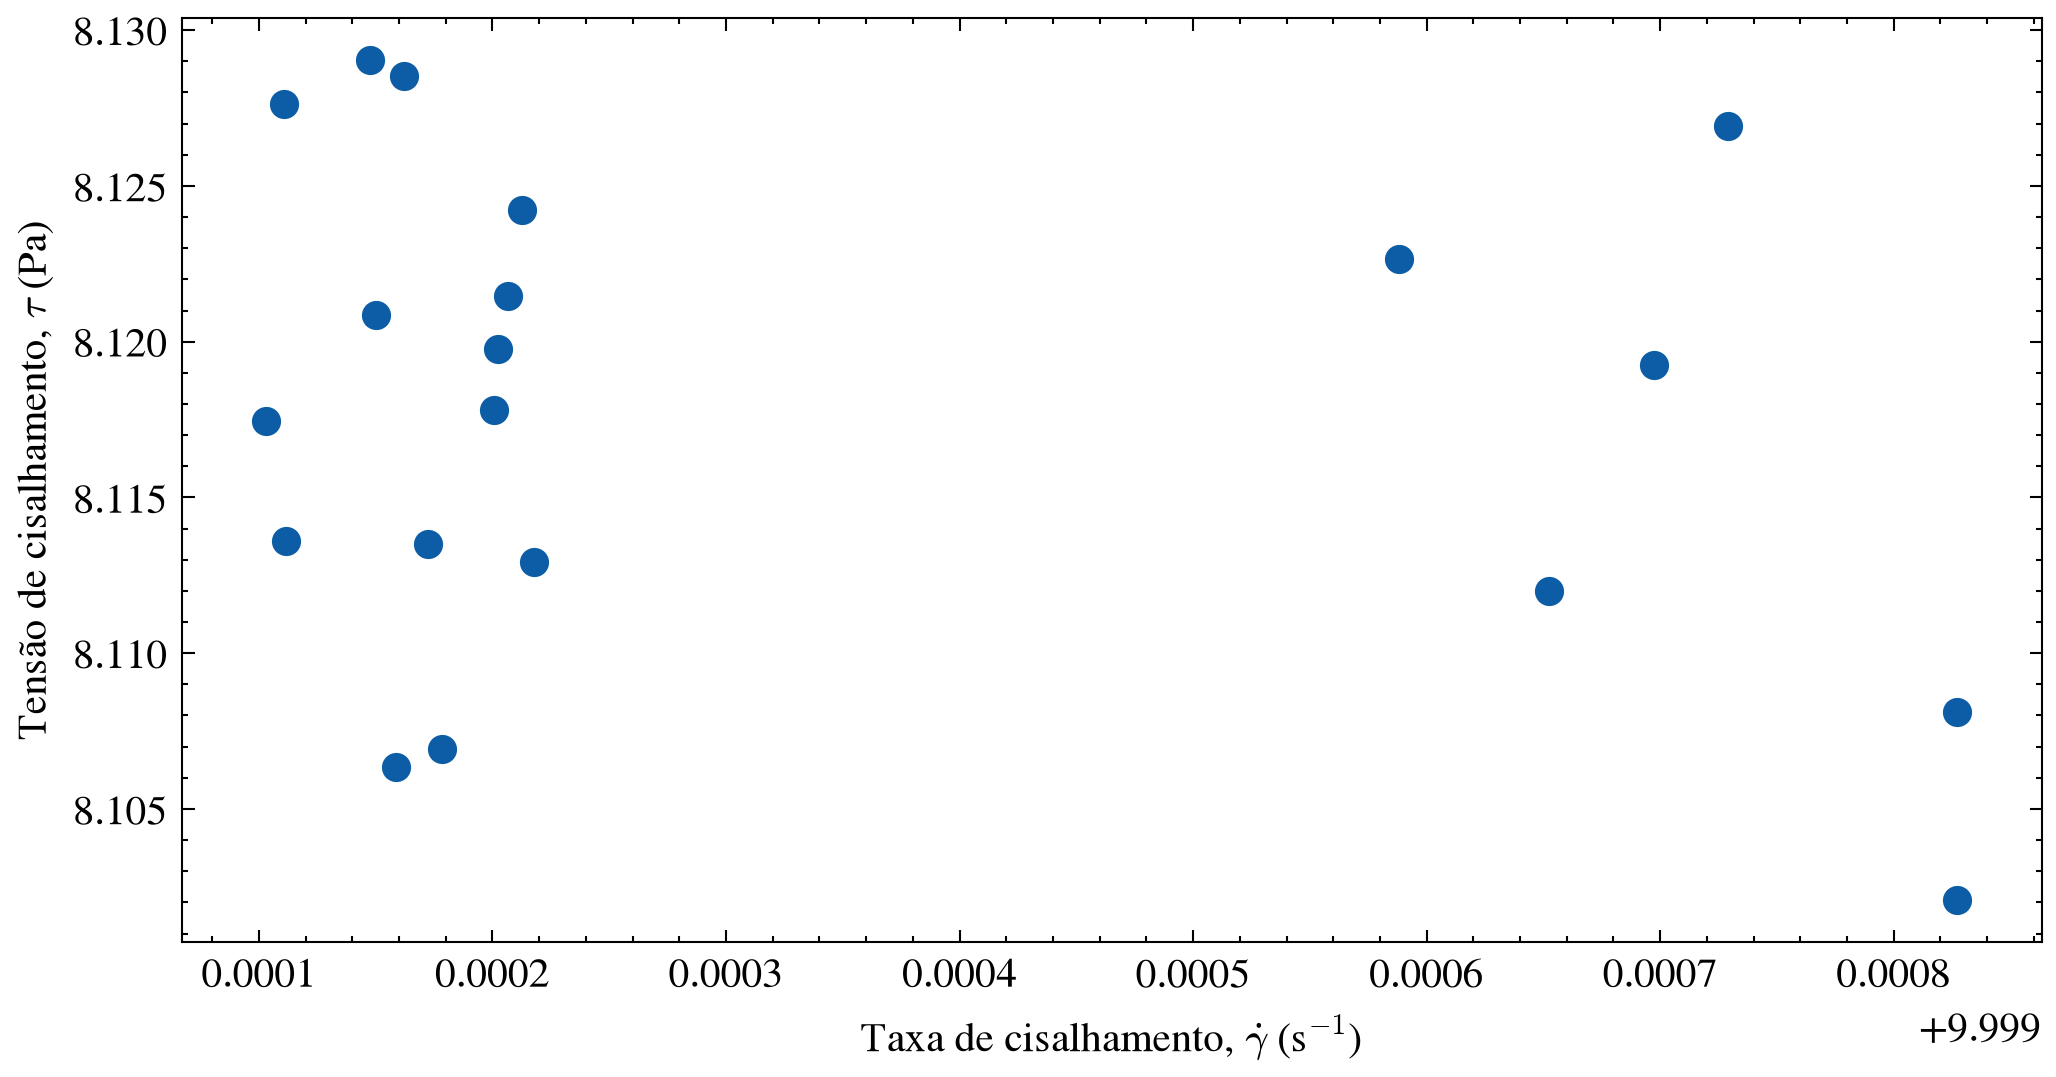

In [1089]:
# Quarto segmento da goma xantana

data_xantan_4 = pd.read_excel("xantan_seg_4.xlsx")

last_20_seg4_xantan = data_xantan_4.tail(20)

plt.figure(figsize=(8, 4), dpi=300)
plt.plot(last_20_seg4_xantan["γ̇ in 1/s"], last_20_seg4_xantan["τ in Pa"], "o")
plt.xlabel(r"Taxa de cisalhamento, $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.legend()
plt.show()



In [1090]:
tau4_medio_xantan = last_20_seg4_xantan["τ in Pa"].mean()
tau4_std_xantan = last_20_seg4_xantan["τ in Pa"].std()

display(Math(rf"\tau = {tau4_medio_xantan:.4g} \pm {tau4_std_xantan:.2g}\ \mathrm{{Pa}}"))

<IPython.core.display.Math object>

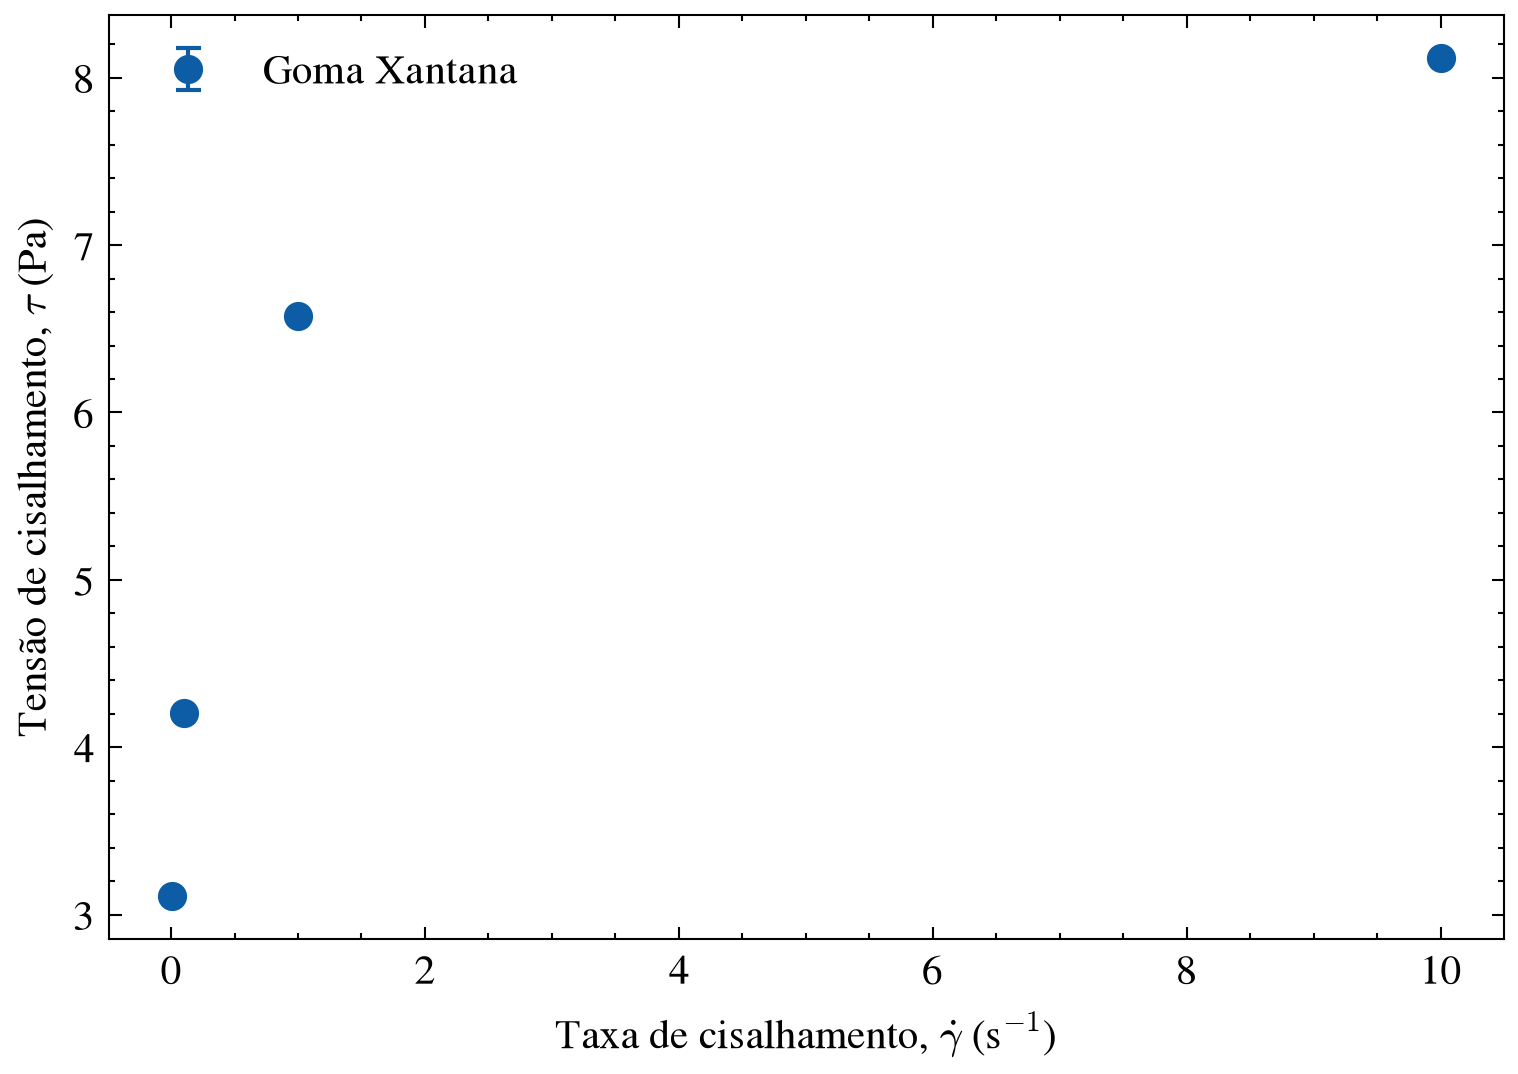

In [1091]:
plt.style.use(["science", "no-latex"])

gd_x = [
    last_20_seg1_xantan["γ̇ in 1/s"].mean(),
    last_20_seg2_xantan["γ̇ in 1/s"].mean(),
    last_20_seg3_xantan["γ̇ in 1/s"].mean(),
    last_20_seg4_xantan["γ̇ in 1/s"].mean(),
]

tau_x = [tau1_medio_xantan, tau2_medio_xantan, tau3_medio_xantan, tau4_medio_xantan]
tau_std_x = [tau1_std_xantan, tau2_std_xantan, tau3_std_xantan, tau4_std_xantan]

plt.figure(figsize=(6, 4), dpi=300)
plt.errorbar(gd_x, tau_x, yerr=tau_std_x, fmt="o", capsize=3, label="Goma Xantana")
plt.xlabel(r"Taxa de cisalhamento, $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.legend()
plt.show()

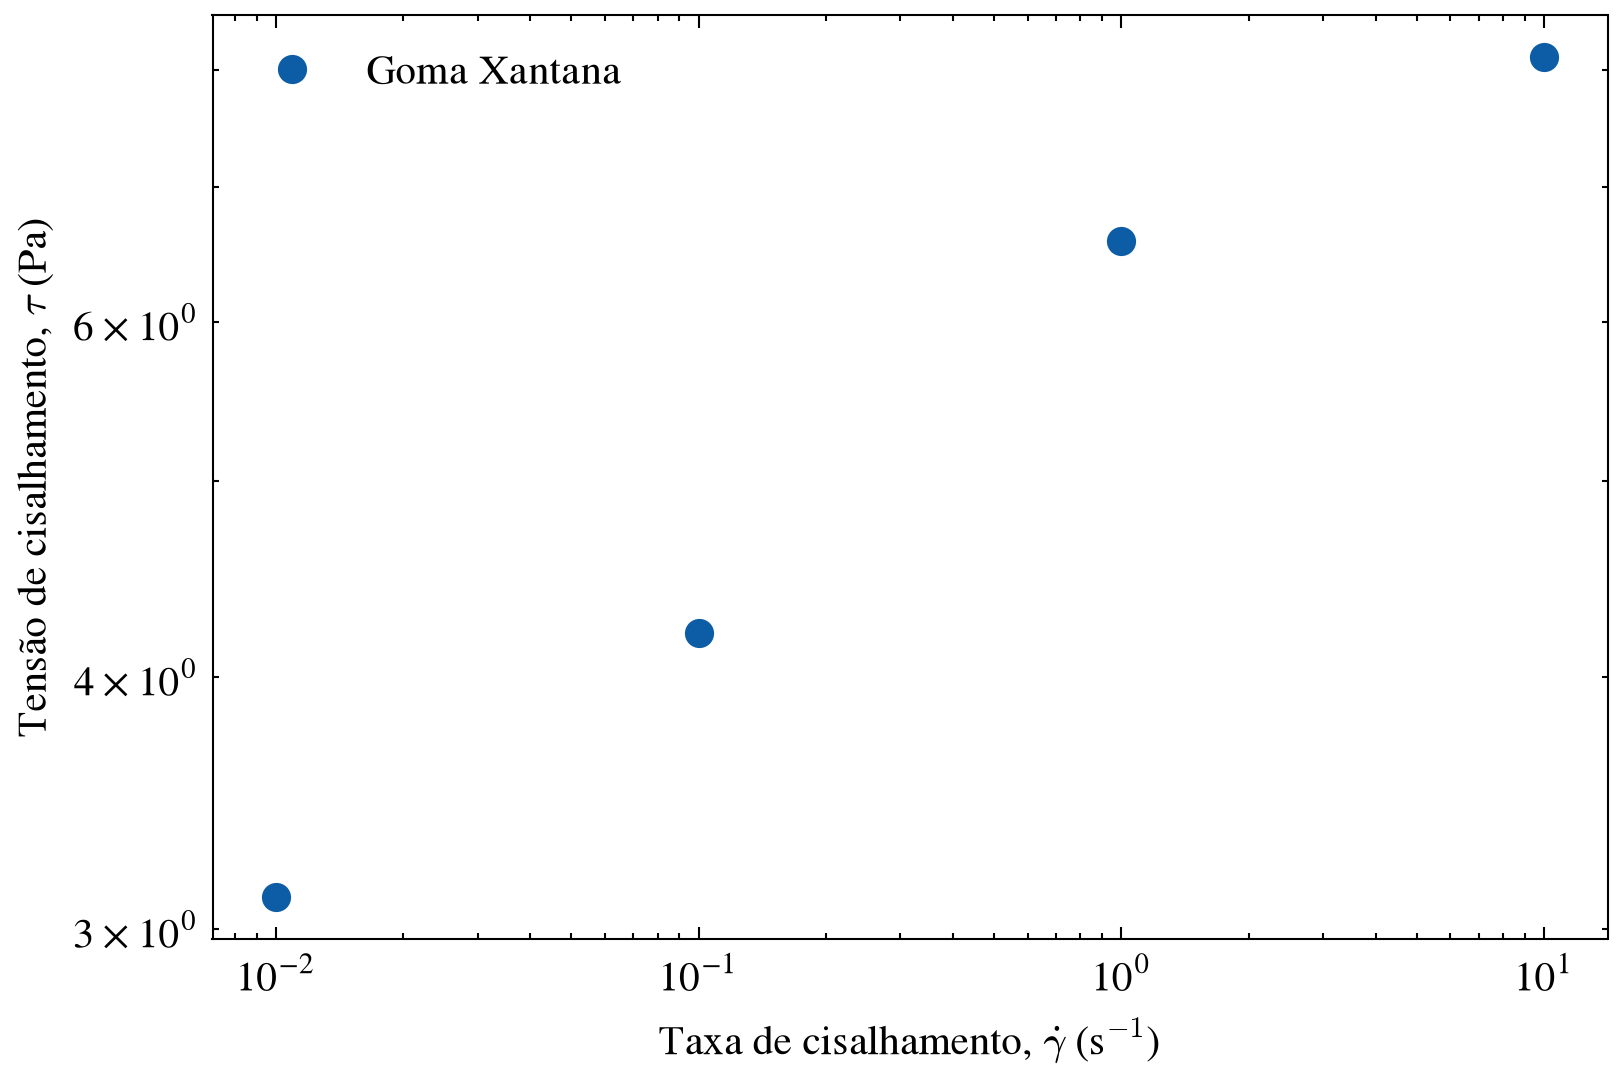

In [1092]:
plt.style.use(["science", "no-latex"])

gd_x = [
    last_20_seg1_xantan["γ̇ in 1/s"].mean(),
    last_20_seg2_xantan["γ̇ in 1/s"].mean(),
    last_20_seg3_xantan["γ̇ in 1/s"].mean(),
    last_20_seg4_xantan["γ̇ in 1/s"].mean(),
]

tau_x = [tau1_medio_xantan, tau2_medio_xantan, tau3_medio_xantan, tau4_medio_xantan]
tau_std_x = [tau1_std_xantan, tau2_std_xantan, tau3_std_xantan, tau4_std_xantan]

plt.figure(figsize=(6, 4), dpi=300)
plt.loglog(gd_x, tau_x,"o", label="Goma Xantana")
plt.xlabel(r"Taxa de cisalhamento, $\dot{\gamma}$ (s$^{-1}$)")
plt.ylabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.legend()
plt.show()

Usando o modelo de Hershel-Bulkley

$$\tau = \tau_0 + K \, \dot{\gamma}^n$$

C:\Users\abner.pereira\AppData\Local\Temp\ipykernel_20688\3727245492.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


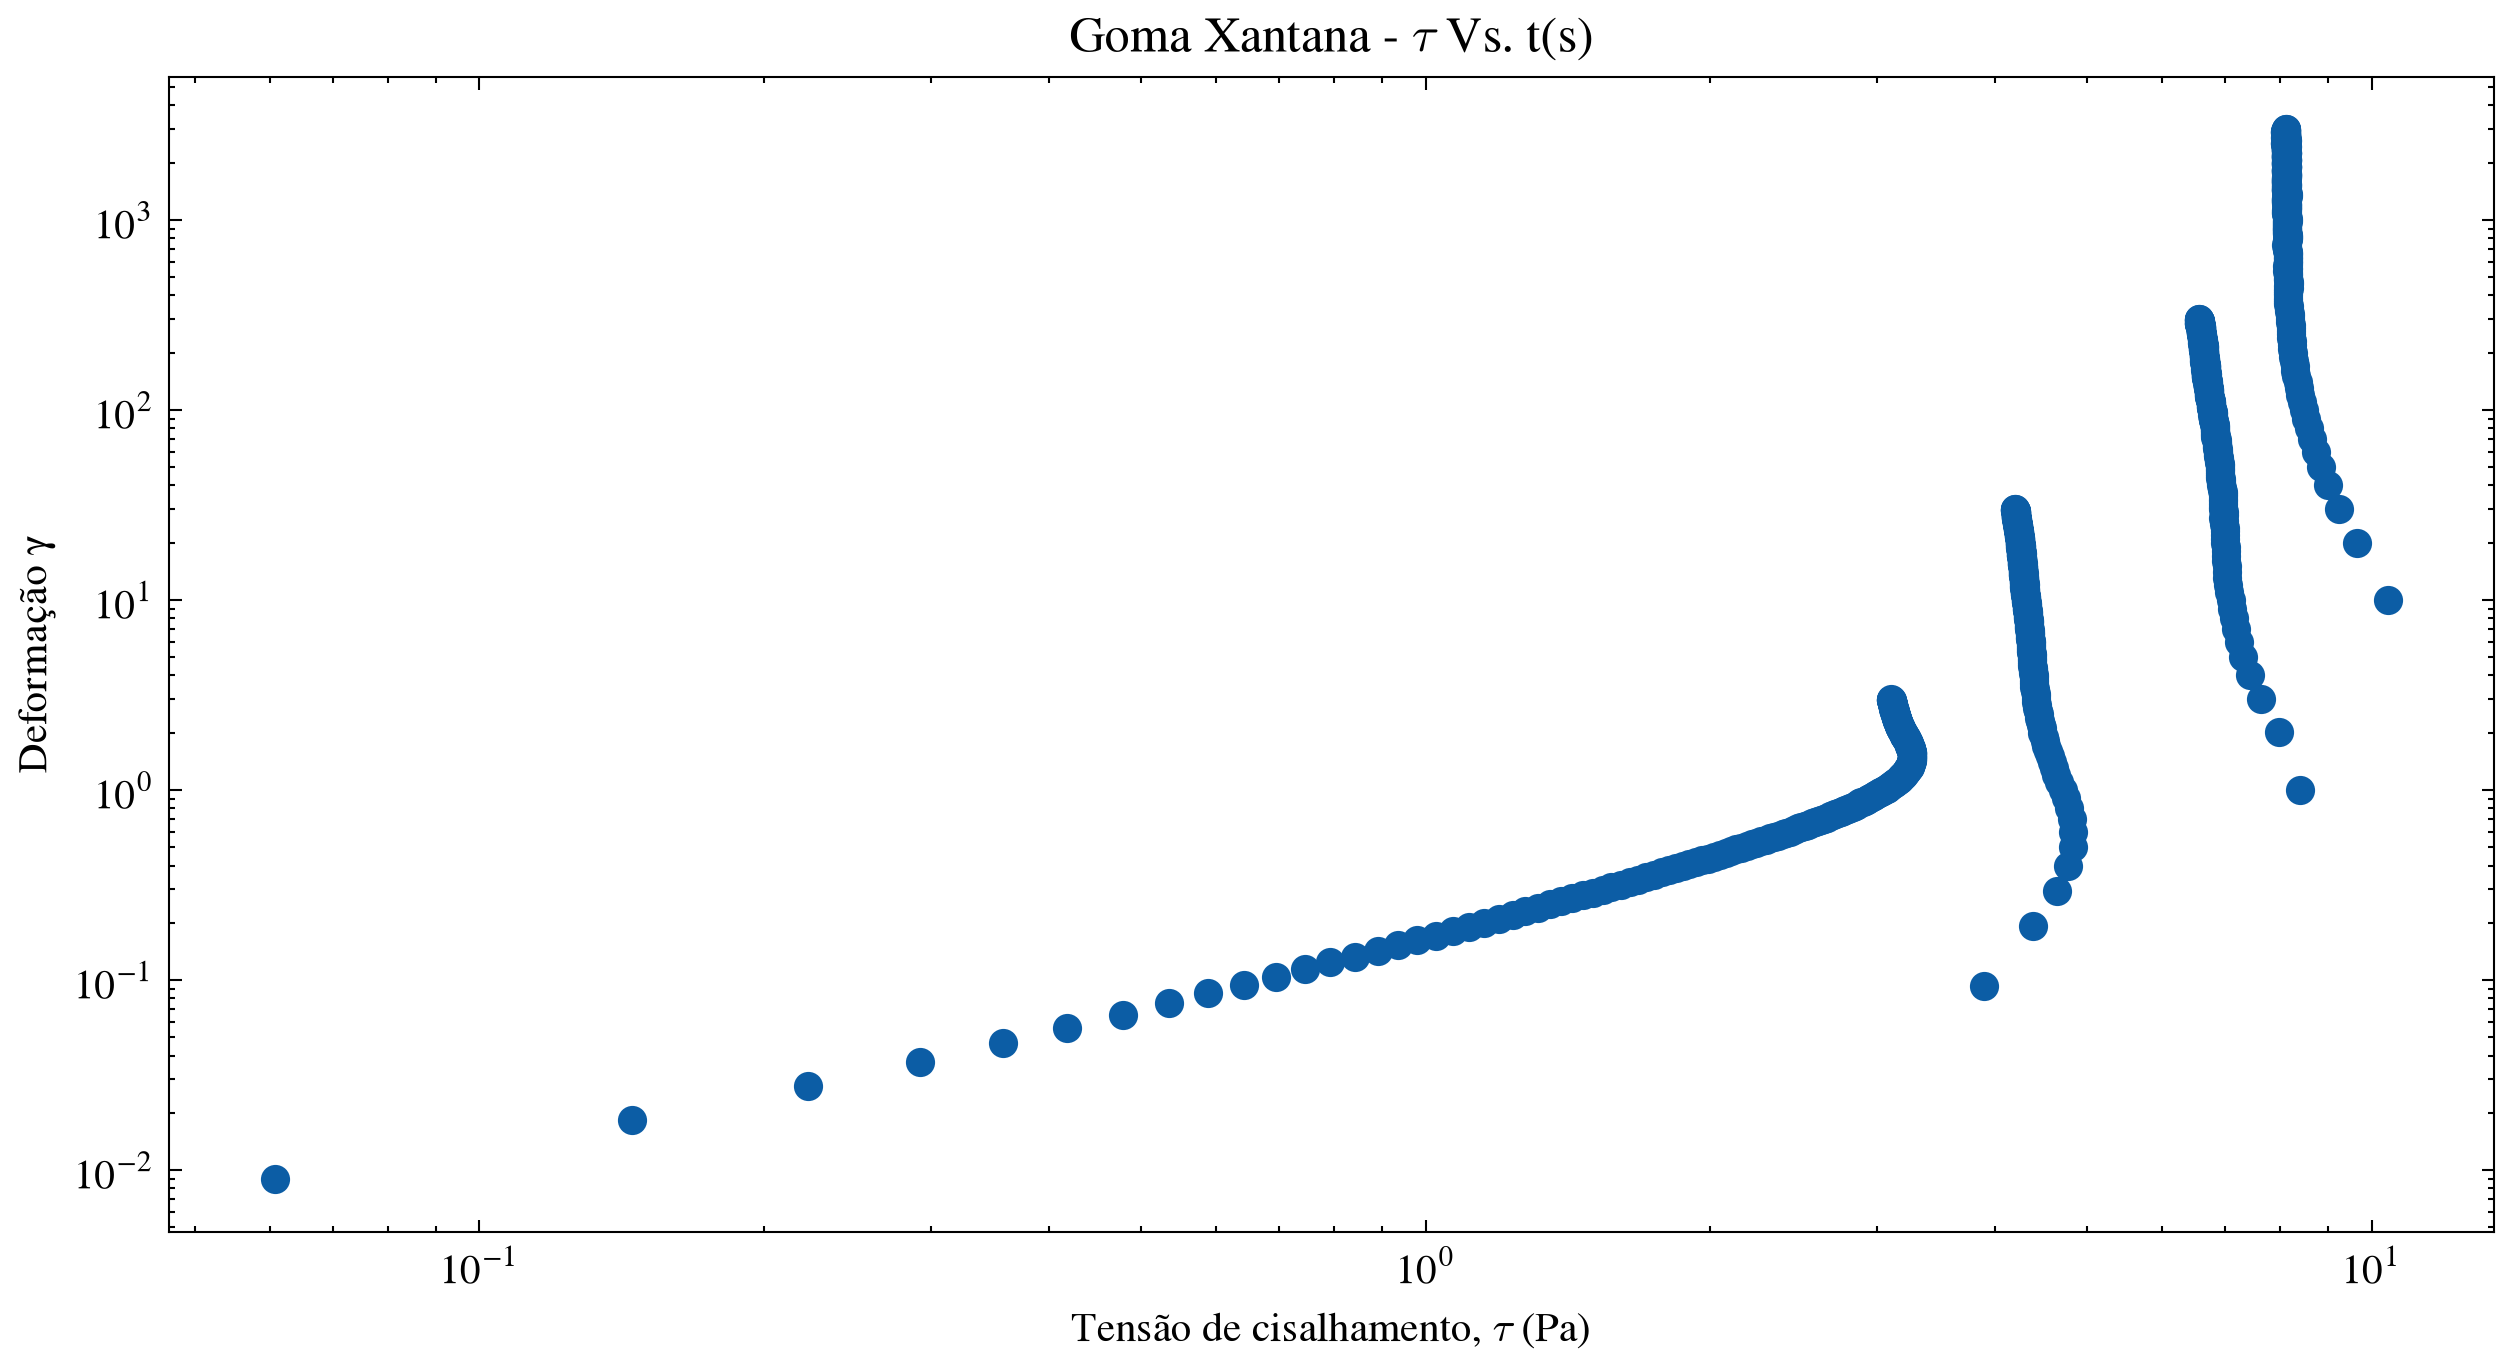

In [1093]:
plt.style.use(["science", "no-latex"])

plt.figure(figsize=(10,5), dpi=300)

plt.loglog(xantan["τ in Pa"], xantan["γ"], 'o')
plt.ylabel(r"Deformação γ")
plt.xlabel(r"Tensão de cisalhamento, $\tau$ (Pa)")
plt.title(r"Goma Xantana - $\tau$ Vs. t(s)")
plt.legend()
plt.show()

In [ ]:
# Pegando para o primeiro degrau

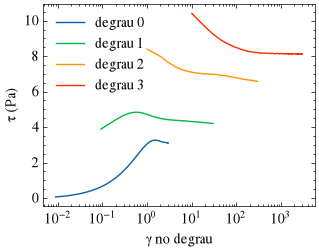

In [1094]:
from scipy.integrate import cumulative_trapezoid

xantan["γ"] = cumulative_trapezoid(xantan["γ̇ in 1/s"], xantan["t in s"], initial=0)
xantan["seg"] = (xantan["t_seg in s"].diff() < 0).cumsum()
xantan["γ_seg"] = xantan["γ̇ in 1/s"] * xantan["t_seg in s"]   # vale aqui, pois γ̇ é constante dentro do degrau

for s, g in xantan.groupby("seg"):
    plt.semilogx(g["γ_seg"], g["τ in Pa"], label=f"degrau {s}")
plt.xlabel("γ no degrau"); plt.ylabel("τ (Pa)"); plt.legend()

τ de pico (degrau 0): 3.27 Pa em γ = 1.51


Text(0, 0.5, 'τ (Pa)')

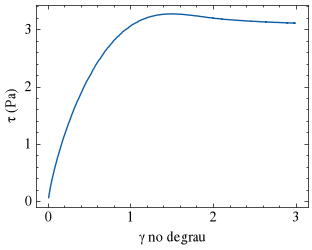

In [1095]:
g0 = xantan[xantan["seg"] == 0]
i = g0["τ in Pa"].idxmax()
print(f"τ de pico (degrau 0): {g0.loc[i, 'τ in Pa']:.2f} Pa em γ = {g0.loc[i, 'γ_seg']:.2f}")

plt.plot(g0["γ_seg"], g0["τ in Pa"])      # x linear deixa a região elástica visível
plt.xlabel("γ no degrau"); plt.ylabel("τ (Pa)")